# [01-1] 데이터 탐색과 시각화 — EOL 최종검사 불량 선별

**K-뉴딜 아카데미 스마트팩토리 캡스톤 · 공통 미니 프로젝트 (1~2회차 · 4개 팀 동일 데이터)**

| 항목 | 내용 |
|---|---|
| 데이터 | `K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx` |
| 분석단위 | 제품 1대의 조립 + 최종검사 기록 1건 |
| 규모 | 1,200행 × 20열 |
| 기간 | 2026년 7월 1일 ~ 7월 31일 |
| 주요 사용자 | 품질팀 · 생산팀 · 설비팀 |
| 핵심 KPI | 불량률, 불량 탐지율(Recall), 헛경보율, 추가검사 건수 |

---

## 이 노트북의 학습목표

1. 처음 받은 데이터의 **크기·구조·변수 의미**를 파악한다.
2. **데이터 품질**(결측·중복·불가능한 값)을 점검하고 처리 방침을 정한다.
3. **분포와 그룹 비교**를 통해 "어디에 문제가 몰려 있는지" 찾는다.
4. **산점도·상관분석·교차표**로 변수 사이의 관계를 읽는다.
5. 관찰된 관계와 **원인을 구분**하고, 다음 단계(모델링)에 쓸 가설을 정리한다.

## 왜 EDA부터 하는가 — 데이터 분석의 순서

EDA(Exploratory Data Analysis, 탐색적 데이터 분석)는 1977년 통계학자 John Tukey가
제안한 개념입니다. 핵심 주장은 이렇습니다.

> **"가설을 검정하기 전에, 데이터가 무슨 말을 하는지 먼저 들어라."**

제조 현장에서 이 말은 더 중요합니다. 설비·공정 데이터는 거의 항상
센서 오류, 기록 누락, 단위 혼용, 비가동 구간이 섞여 있습니다. 이것을 모르고
바로 모델을 만들면 **"쓰레기를 넣으면 쓰레기가 나온다"(garbage in, garbage out)** 가 됩니다.

실무 데이터 분석 프로젝트의 시간 배분은 대략 이렇습니다.

| 단계 | 비중 | 이 과정에서 |
|---|---|---|
| 문제정의 · 데이터 이해 · 정제 | **60~80%** | 1편 (이 노트북) |
| 모델 학습 · 평가 | 10~20% | 2편 |
| 해석 · 개선 · 적용 | 10~20% | 3편 |

**모델을 만드는 시간보다 데이터를 이해하는 시간이 훨씬 깁니다.** 이것이 정상입니다.

---

## 0. 이 노트북을 사용하는 방법

이 노트북은 **Google Colab**에서 위에서 아래로 순서대로 실행하도록 만들어졌습니다.

**실행 방법**

| 하고 싶은 것 | 방법 |
|---|---|
| 셀 하나 실행 | 셀을 클릭하고 `Shift + Enter` |
| 위에서부터 전체 실행 | 메뉴 `런타임 > 모두 실행` |
| 처음부터 다시 | 메뉴 `런타임 > 런타임 초기화 후 모두 실행` |
| 코드 수정 | 셀 안의 숫자/변수명을 바꾸고 다시 `Shift + Enter` |

**학습 태도에 대한 당부**

- 코드를 **외우려 하지 마세요.** 이 교육의 목표는 "코드를 쓰는 사람"이 아니라
  "데이터로 공정을 판단하는 사람"이 되는 것입니다.
- 각 셀의 주석(`#` 으로 시작하는 줄)과 셀 위의 설명을 먼저 읽고, 출력된 **숫자와 그림이
  현장에서 무슨 뜻인지**를 말로 설명해 보세요.
- 셀 아래의 **생각해 볼 질문**은 발표 자료의 재료가 됩니다. 답을 메모해 두세요.
- 에러가 나면 당황하지 말고 **맨 아랫줄(마지막 Error 문장)** 부터 읽으세요. 대부분
  오타, 변수명 불일치, 셀 실행 순서 문제입니다.

> 이 데이터는 **교육용 합성데이터**입니다. 실제 기업의 설비 상태나 품질 수준을 나타내지
> 않습니다. 따라서 여기서 얻은 수치는 "분석 연습의 결과"이며, 현장 결론으로 그대로
> 인용하면 안 됩니다. 반대로 **분석 절차와 해석 방법**은 실제 현장에서 그대로 쓰입니다.

---

## 0-1. 현장 상황과 문제정의

가상의 **소형 전자제품 조립공장**입니다. 제품은 모든 조립공정을 거친 뒤
라인 끝에서 **EOL(End of Line) 최종검사**를 받습니다. 2026년 7월 한 달간 1,200대를
생산·검사했고 그중 **48대(4.0%)가 불합격**했습니다.

현장 회의에서 이런 의견이 나왔습니다.

> "야간조 불량률이 주간조보다 두 배 가까이 높다. 야간 작업자 교육을 강화해야 한다."

실제 숫자는 **주간 18/640건(2.81%), 야간 30/560건(5.36%)** 입니다. 숫자는 맞습니다.
그런데 야간에는 **생산한 제품모델 구성, 사용한 설비, 작업조건**도 주간과 다릅니다.
즉 "야간"이라는 꼬리표 안에 다른 원인이 섞여 있을 수 있습니다.

그리고 검사는 시간과 비용이 듭니다. 모든 제품을 2번 검사할 수는 없으므로,
**EOL 검사 전에 "추가로 확인할 제품"을 골라내는 간단한 기준**이 필요합니다.

### 이번 분석의 핵심 질문

> **야간조 불량률이 높은 이유가 정말 근무조 때문인지, 아니면 야간에 만든 제품모델·설비·작업조건이 달랐기 때문인지 확인하고, EOL 검사 전에 추가확인할 제품을 선별하는 기준을 만든다.**

### 의사결정 시점 (가장 중요한 개념)

> **제품이 EOL 검사대에 도착하기 직전 (조립은 끝났고 검사결과는 아직 모르는 시점)**

데이터 분석에서 **"언제 판단하는가"** 를 정하는 것은 **"무엇을 예측하는가"** 보다
중요할 때가 많습니다. 판단 시점이 정해지면 **그 시점에 존재하는 데이터만** 쓸 수 있고,
그 이후에 생기는 값을 쓰면 **데이터 누출(data leakage)** 이 됩니다.
누출된 모델은 시험 성적은 완벽하지만 현장에서는 아무 쓸모가 없습니다.
(2편에서 자세히 다룹니다. 1편에서는 "이 변수는 언제 생기는가"를 계속 의식하세요.)

### 문제정의를 문장으로 쓰는 연습

현장 문제를 분석 과제로 바꿀 때는 아래 5칸을 채웁니다. 캡스톤 최종 발표의 첫 장이 됩니다.

| 칸 | 내용 |
|---|---|
| 누가 | 품질팀 · 생산팀 · 설비팀 |
| 언제 | 제품이 EOL 검사대에 도착하기 직전 (조립은 끝났고 검사결과는 아직 모르는 시점) |
| 무엇을 판단 | 야간조 불량률이 높은 이유가 정말 근무조 때문인지, 아니면 야간에 만든 제품모델·설비·작업조건이 달랐기 때문인지 확인하고, EOL 검사 전에 추가확인할 제품을 선별하는 기준을 만든다. |
| 무엇으로 측정 | 불량률, 불량 탐지율(Recall), 헛경보율, 추가검사 건수 |
| 틀렸을 때의 비용 | 놓침(미탐)의 비용 vs 헛경보(오탐)의 비용 — 2편에서 수치로 비교 |

---

## 1. 환경 준비 (라이브러리 / 한글폰트)

분석은 "도구를 꺼내는 일"에서 시작합니다. 파이썬 자체에는 표 계산이나 그래프 기능이
없고, 필요한 기능을 **라이브러리**(기능 묶음)로 불러와서 씁니다. 이 교육에서 쓰는 4가지는
다음과 같습니다.

| 라이브러리 | 별칭 | 역할 | 현장 비유 |
|---|---|---|---|
| `pandas` | `pd` | 표(엑셀 시트) 형태 데이터 처리 | 엑셀 |
| `numpy` | `np` | 숫자 배열·수학 계산 | 공학용 계산기 |
| `matplotlib` | `plt` | 그래프 그리기 | 모눈종이 + 자 |
| `seaborn` | `sns` | 통계 그래프를 짧은 코드로 | 그래프 템플릿 |
| `scikit-learn` | `sklearn` | 머신러닝 모델·전처리·평가 | 분석 엔진 |

`import A as B` 는 "A라는 도구상자를 가져와서 앞으로 B라는 짧은 이름으로 부르겠다"는 뜻입니다.

**한글 폰트**: 그래프 제목·축이름에 한글을 쓰면 기본 설정에서는 □□□ 로 깨집니다.
아래 셀이 Colab/로컬 환경을 자동으로 판별해 한글 폰트를 설정합니다. (한 번만 실행하면 됩니다.)

In [1]:
# =============================================================================
# [1-1] 라이브러리 불러오기 + 한글 폰트 설정
# =============================================================================
import os
import sys
import glob
import warnings

import numpy as np                 # 수치 계산
import pandas as pd                # 표 데이터 처리
import matplotlib as mpl
import matplotlib.pyplot as plt    # 그래프
import seaborn as sns              # 통계 그래프

warnings.filterwarnings("ignore")  # 교육용: 경고 메시지를 숨겨 출력을 깔끔하게 한다

IN_COLAB = "google.colab" in sys.modules   # 지금 Colab에서 실행 중인가?


def setup_korean_font():
    """그래프에 한글이 깨지지 않도록 폰트를 설정한다.

    1) 이미 설치된 한글 폰트가 있으면 그것을 쓴다(로컬 PC/Mac).
    2) 없고 Colab이면 koreanize-matplotlib 패키지를 설치해서 쓴다.
    3) 둘 다 실패하면 영문 폰트를 그대로 쓴다(그래프는 그려지지만 한글이 깨진다).
    """
    from matplotlib import font_manager

    candidates = ["NanumGothic", "NanumBarunGothic", "Malgun Gothic",
                  "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR"]
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in candidates:
        if name in installed:
            mpl.rcParams["font.family"] = name
            mpl.rcParams["axes.unicode_minus"] = False   # 음수 기호(-) 깨짐 방지
            return f"설정 완료: {name}"

    if IN_COLAB:
        try:
            import subprocess
            subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                            "koreanize-matplotlib"], check=True)
            import koreanize_matplotlib  # noqa: F401  (import만 해도 폰트가 적용됨)
            mpl.rcParams["axes.unicode_minus"] = False
            return "설정 완료: koreanize-matplotlib (NanumGothic)"
        except Exception as e:      # 네트워크 차단 등
            return f"한글 폰트 설정 실패({e}) - 그래프의 한글이 깨질 수 있습니다"
    return "한글 폰트를 찾지 못했습니다 - 그래프의 한글이 깨질 수 있습니다"


print(setup_korean_font())

# 그래프 기본 모양 / 표 출력 옵션
sns.set_theme(style="whitegrid", font=mpl.rcParams["font.family"][0] if isinstance(mpl.rcParams["font.family"], list) else mpl.rcParams["font.family"])
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.figsize"] = (9, 5)     # 그래프 기본 크기(가로, 세로 인치)
mpl.rcParams["figure.dpi"] = 110            # 해상도
mpl.rcParams["font.size"] = 11

pd.set_option("display.max_columns", 60)    # 표의 열을 생략하지 않고 보여준다
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("pandas", pd.__version__, "| numpy", np.__version__, "| Colab:", IN_COLAB)

설정 완료: Malgun Gothic
pandas 2.3.3 | numpy 2.5.4 | Colab: False


---

## 2. 데이터 불러오기

분석할 파일은 **`K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx`** 입니다. 엑셀 파일의 **`MiniCase_Data`** 시트가 원천데이터입니다.

Colab은 내 PC가 아니라 **구글 클라우드의 임시 컴퓨터**에서 돌아갑니다. 따라서 내 PC에 있는
파일을 Colab이 자동으로 볼 수는 없고, 다음 중 하나로 **파일을 올려줘야** 합니다.

| 방법 | 언제 쓰나 | 특징 |
|---|---|---|
| ① 직접 업로드 | 한 번만 쓸 때 | 아래 셀 실행 → 파일 선택. 런타임이 끊기면 다시 올려야 함 |
| ② 구글 드라이브 마운트 | 수업 내내 쓸 때 (권장) | `drive.mount()` 후 내 드라이브 경로를 그대로 사용 |
| ③ 로컬 주피터 | 내 PC에서 실행할 때 | 노트북과 같은 폴더에 두면 자동 인식 |

아래 셀은 ①②③을 **자동으로 판단**합니다. 흔히 쓰는 경로를 먼저 찾아보고, 못 찾으면
업로드 창을 띄웁니다. 드라이브를 쓰려면 아래 주석 2줄의 `#` 을 지우고 실행하세요.

In [2]:
# =============================================================================
# [2-1] 데이터 파일 찾기 → 읽기
# =============================================================================
# (선택) 구글 드라이브를 쓰려면 아래 2줄의 주석을 해제하고 실행하세요.
# from google.colab import drive
# drive.mount('/content/drive')

DATA_FILE = "K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx"      # 찾을 파일명
NAME_HINT = "MiniCase" # 파일명이 조금 달라도 찾기 위한 키워드

SEARCH_DIRS = [
    os.environ.get("KNEWDEAL_DATA_DIR", ""),   # (강사용) 환경변수로 지정한 폴더
    ".", "..", "../..",                        # 노트북 주변 폴더
    "/content",                                # Colab 업로드 기본 위치
    "/content/drive/MyDrive",
    "/content/drive/MyDrive/K뉴딜",
    "/content/drive/MyDrive/Colab Notebooks",
    os.path.expanduser("~/Downloads"),
]


def find_data_file(file_name, name_hint):
    """후보 폴더를 돌면서 파일을 찾는다. 정확한 파일명 → 키워드 부분일치 순으로 탐색."""
    for d in SEARCH_DIRS:
        if not d:
            continue
        p = os.path.join(d, file_name)
        if os.path.exists(p):
            return p
    for d in SEARCH_DIRS:                       # 파일명이 조금 바뀐 경우 대비
        if not d or not os.path.isdir(d):
            continue
        hits = [p for p in glob.glob(os.path.join(d, "*")) if name_hint in os.path.basename(p)]
        if hits:
            return sorted(hits)[0]
    return None


DATA_PATH = find_data_file(DATA_FILE, NAME_HINT)

if DATA_PATH is None and IN_COLAB:
    print("파일을 찾지 못했습니다. 아래 버튼으로 데이터 파일을 업로드하세요.")
    from google.colab import files
    uploaded = files.upload()               # 파일 선택 창이 열린다
    DATA_PATH = list(uploaded.keys())[0]

if DATA_PATH is None:
    raise FileNotFoundError(
        "데이터 파일을 찾을 수 없습니다.\n"
        f" - 찾는 파일: {DATA_FILE}\n"
        " - 해결: (1) Colab 왼쪽 '파일' 탭에 파일을 끌어다 놓거나\n"
        "         (2) 구글 드라이브를 마운트하고 SEARCH_DIRS에 경로를 추가하세요."
    )

print("데이터 경로:", DATA_PATH)
df_raw = pd.read_excel(DATA_PATH, sheet_name="MiniCase_Data")
print("불러온 데이터 크기:", df_raw.shape, "  (행 수, 열 수)")
df_raw.head(3)

데이터 경로: .\K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx
불러온 데이터 크기: (1200, 20)   (행 수, 열 수)


,record_id,timestamp,shift,line_id,product_model,equipment_id,operator_group,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh,inspection_result,defect_type,inspection_time_sec,rework_flag,rework_time_min,final_disposition
0,R00001,2026-07-01 21:00:25,야간,L1,P1,M04,G01,31.460,5.980,51.400,35.200,2.700,0,1.000,합격,NaN,37,N,0,합격
1,R00002,2026-07-02 12:12:10,주간,L2,P2,M04,G02,32.370,5.660,50.600,38.600,2.590,0,0.915,합격,NaN,42,N,0,합격
2,R00003,2026-07-03 10:03:12,주간,L1,P1,M03,G03,30.260,5.680,49.400,39.500,2.270,1,1.044,합격,NaN,46,N,0,합격


---

## 3. 데이터의 첫인상 — 크기 · 구조 · 자료형

새 데이터를 받으면 **항상 이 4가지를 먼저** 확인합니다.

| 확인 | 코드 | 왜 |
|---|---|---|
| 크기 | `df.shape` | 행=기록 수, 열=변수 수. 기대와 다르면 파일이 잘못된 것 |
| 미리보기 | `df.head()` | 값이 실제로 어떻게 생겼는지(단위·형식) 확인 |
| 자료형 | `df.info()` | 숫자가 문자로 읽혔는지, 결측이 있는지 한눈에 |
| 요약통계 | `df.describe()` | 평균·최소·최대로 **불가능한 값**을 바로 찾는다 |

**자료형(dtype)을 꼭 보세요.** 숫자 열에 "N/A" 같은 문자가 하나라도 섞이면 pandas는
그 열 전체를 문자(object)로 읽습니다. 그 상태로 평균을 구하면 에러가 나거나
엉뚱한 결과가 나옵니다. 이 데이터의 분석단위는 **제품 1대의 조립 + 최종검사 기록 1건** 입니다. 즉 한 행이
제품 1대의 조립 + 최종검사 기록 1건 하나를 의미합니다.

In [3]:
# =============================================================================
# [3-1] 크기와 구조
# =============================================================================
df = df_raw.copy()           # 원본은 보존하고 복사본으로 작업한다 (분석의 기본 습관)

print("행(기록) 수 :", df.shape[0])
print("열(변수) 수 :", df.shape[1])
print()
print("[변수 목록]")
for i, c in enumerate(df.columns, 1):
    print(f"  {i:2d}. {c:<32s} {str(df[c].dtype):<12s} 결측 {df[c].isna().sum():>4d}건  "
          f"고유값 {df[c].nunique():>5d}개")

행(기록) 수 : 1200
열(변수) 수 : 20

[변수 목록]
   1. record_id                        object       결측    0건  고유값  1200개
   2. timestamp                        datetime64[ns] 결측    0건  고유값  1199개
   3. shift                            object       결측    0건  고유값     2개
   4. line_id                          object       결측    0건  고유값     2개
   5. product_model                    object       결측    0건  고유값     2개
   6. equipment_id                     object       결측    0건  고유값     4개
   7. operator_group                   object       결측    0건  고유값     6개
   8. torque_nm                        float64      결측   12건  고유값   557개
   9. pressure_bar                     float64      결측    0건  고유값    41개
  10. cycle_time_sec                   float64      결측    0건  고유값   121개
  11. temperature_c                    float64      결측    0건  고유값    71개
  12. vibration_mm_s                   float64      결측   18건  고유값   141개
  13. downtime_min                     int64        결측    0건  고유값     2개
  14. energy

In [4]:
# =============================================================================
# [3-2] 자료형 요약과 미리보기
# =============================================================================
df.info()          # 열별 자료형 + 비결측 개수 + 메모리 사용량

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   record_id            1200 non-null   object        
 1   timestamp            1200 non-null   datetime64[ns]
 2   shift                1200 non-null   object        
 3   line_id              1200 non-null   object        
 4   product_model        1200 non-null   object        
 5   equipment_id         1200 non-null   object        
 6   operator_group       1200 non-null   object        
 7   torque_nm            1188 non-null   float64       
 8   pressure_bar         1200 non-null   float64       
 9   cycle_time_sec       1200 non-null   float64       
 10  temperature_c        1200 non-null   float64       
 11  vibration_mm_s       1182 non-null   float64       
 12  downtime_min         1200 non-null   int64         
 13  energy_kwh           1200 non-nul

In [5]:
# 앞 5행 미리보기 - 값의 '생김새'(단위, 자릿수, 코드값)를 눈으로 확인한다
df.head()

,record_id,timestamp,shift,line_id,product_model,equipment_id,operator_group,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh,inspection_result,defect_type,inspection_time_sec,rework_flag,rework_time_min,final_disposition
0,R00001,2026-07-01 21:00:25,야간,L1,P1,M04,G01,31.460,5.980,51.400,35.200,2.700,0,1.000,합격,NaN,37,N,0,합격
1,R00002,2026-07-02 12:12:10,주간,L2,P2,M04,G02,32.370,5.660,50.600,38.600,2.590,0,0.915,합격,NaN,42,N,0,합격
2,R00003,2026-07-03 10:03:12,주간,L1,P1,M03,G03,30.260,5.680,49.400,39.500,2.270,1,1.044,합격,NaN,46,N,0,합격
3,R00004,2026-07-04 00:49:22,야간,L1,P1,M04,G04,29.610,5.820,49.100,39.200,1.560,0,0.924,합격,NaN,42,N,0,합격
4,R00005,2026-07-05 12:41:24,주간,L2,P2,M02,G05,31.480,5.940,47.900,36.000,1.350,1,1.011,합격,NaN,38,N,0,합격


In [6]:
# =============================================================================
# [3-3] 수치형 / 범주형 변수를 나눠 요약
# =============================================================================
num_all = df.select_dtypes(include=[np.number]).columns.tolist()   # 숫자형 열
cat_all = df.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"수치형 {len(num_all)}개:", num_all)
print()
print(f"범주형 {len(cat_all)}개:", cat_all)
print()
print("[수치형 요약통계]  min/max 에서 '불가능한 값'을 찾아보세요")
display(df[num_all].describe().T)

수치형 9개: ['torque_nm', 'pressure_bar', 'cycle_time_sec', 'temperature_c', 'vibration_mm_s', 'downtime_min', 'energy_kwh', 'inspection_time_sec', 'rework_time_min']

범주형 10개: ['record_id', 'shift', 'line_id', 'product_model', 'equipment_id', 'operator_group', 'inspection_result', 'defect_type', 'rework_flag', 'final_disposition']

[수치형 요약통계]  min/max 에서 '불가능한 값'을 찾아보세요


,count,mean,std,min,25%,50%,75%,max
torque_nm,"1,188.000",30.042,1.890,25.800,28.477,30.085,31.580,34.150
pressure_bar,"1,200.000",5.802,0.116,5.600,5.700,5.800,5.900,6.000
cycle_time_sec,"1,200.000",53.065,3.452,47.000,50.000,53.200,56.000,59.000
temperature_c,"1,200.000",38.517,2.039,35.000,36.800,38.500,40.300,42.000
vibration_mm_s,"1,182.000",2.014,0.408,1.300,1.662,2.010,2.380,2.700
downtime_min,"1,200.000",0.508,0.500,0.000,0.000,1.000,1.000,1.000
energy_kwh,"1,200.000",0.951,0.059,0.851,0.902,0.951,1.003,1.050
inspection_time_sec,"1,200.000",42.097,4.245,35.000,38.000,42.000,46.000,49.000
rework_time_min,"1,200.000",0.322,1.586,0.000,0.000,0.000,0.000,9.000


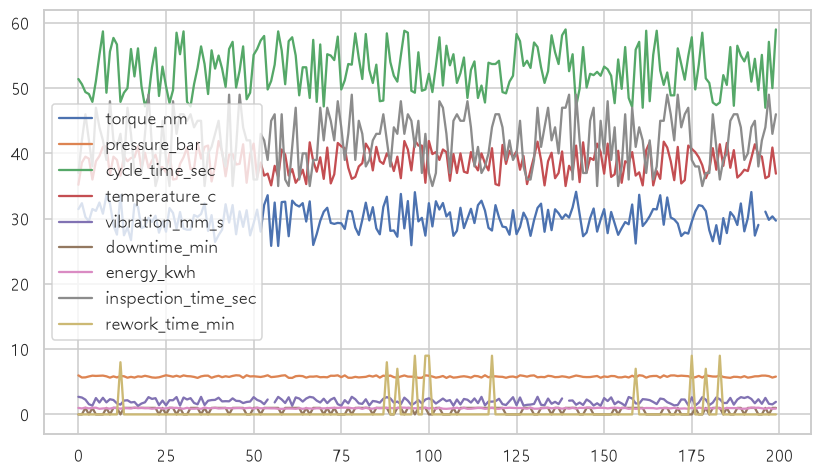

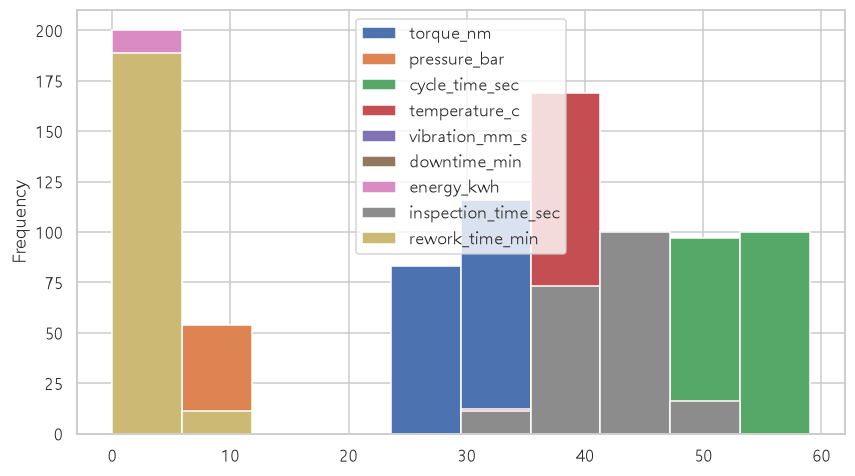

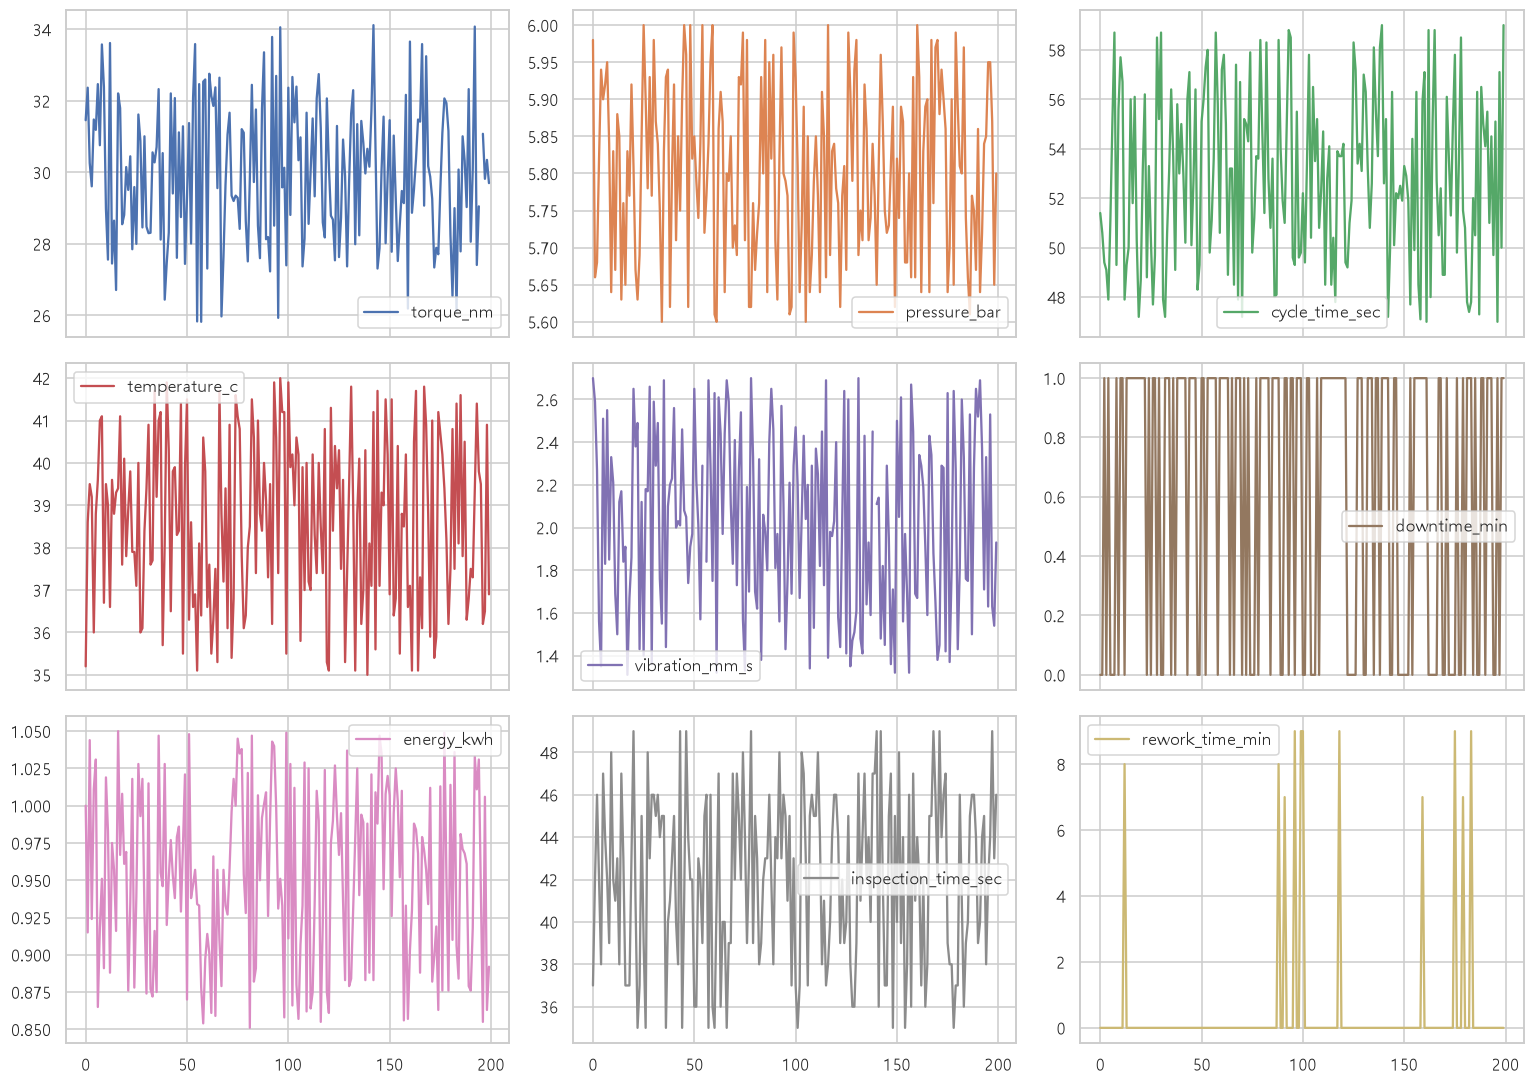

In [40]:
df[num_all][:200].plot()
df[num_all][:200].plot(kind="hist")
df[num_all].iloc[:200].plot(subplots=True, layout=(-1, 3), figsize=(14, 10), sharex=True)
plt.tight_layout()
plt.show()

In [7]:
# [3-4] 범주형 변수의 값 종류와 빈도
for c in cat_all:
    n = df[c].nunique()
    if n > 15:        # ID처럼 값이 너무 많은 열은 개수만 표시
        print(f"[{c}] 고유값 {n}개 (ID 성격으로 보임) 예: {df[c].dropna().unique()[:3]}")
        continue
    vc = df[c].value_counts(dropna=False)
    print(f"[{c}] 고유값 {n}개")
    for k, v in vc.items():
        print(f"      {str(k):<18s} {v:>5d}건  ({v / len(df) * 100:5.1f}%)")
    print()

[record_id] 고유값 1200개 (ID 성격으로 보임) 예: ['R00001' 'R00002' 'R00003']
[shift] 고유값 2개
      주간                   640건  ( 53.3%)
      야간                   560건  ( 46.7%)

[line_id] 고유값 2개
      L1                   650건  ( 54.2%)
      L2                   550건  ( 45.8%)

[product_model] 고유값 2개
      P1                   650건  ( 54.2%)
      P2                   550건  ( 45.8%)

[equipment_id] 고유값 4개
      M04                  300건  ( 25.0%)
      M03                  300건  ( 25.0%)
      M02                  300건  ( 25.0%)
      M01                  300건  ( 25.0%)

[operator_group] 고유값 6개
      G01                  200건  ( 16.7%)
      G02                  200건  ( 16.7%)
      G03                  200건  ( 16.7%)
      G04                  200건  ( 16.7%)
      G05                  200건  ( 16.7%)
      G06                  200건  ( 16.7%)

[inspection_result] 고유값 2개
      합격                  1152건  ( 96.0%)
      불합격                   48건  (  4.0%)

[defect_type] 고유값 4개
      nan             

> **생각해 볼 점**: 요약통계에서 최솟값이 음수인데 음수가 될 수 없는 변수가 있나요?
> 최댓값이 상식적인 범위를 크게 넘는 변수가 있나요? 이런 값은 **뒤에서 "물리적으로
> 불가능한 값"으로 따로 처리**합니다. 지금은 발견하고 적어 두는 것이 목표입니다.

---

## 4. 데이터 품질 점검 — 결측 · 중복 · 불가능한 값

### 4-1. 결측값(missing value)을 보는 3단계

초보자가 가장 많이 하는 실수는 `df.dropna()` 한 줄로 결측이 있는 행을 전부 지우는 것입니다.
그러면 두 가지 문제가 생깁니다.

1. **데이터가 줄어든다** (결측이 여러 열에 흩어져 있으면 생각보다 많이 줄어든다)
2. **편향이 생긴다** — 결측이 특정 설비·시간대에 몰려 있으면, 그 조건의 데이터만 사라진다

그래서 결측은 이 순서로 봅니다.

| 단계 | 질문 | 방법 |
|---|---|---|
| ① 얼마나 | 어느 열에 몇 %가 없나 | `df.isna().sum()` |
| ② 왜 | 센서 고장? 기록 누락? **원래 없는 값?** | 업무 흐름 확인, 다른 열과 교차 |
| ③ 어떻게 | 삭제 / 대치 / 표시변수 / 그대로 | ②의 답에 따라 결정 |

②가 가장 중요합니다. 결측에는 세 종류가 있습니다.

- **구조적 결측**: 원래 존재할 수 없는 값. (예: 합격품의 불량유형, 생산량 0일 때의 원단위)
  → **채우면 안 됩니다.** 채우면 거짓 정보를 만드는 것입니다.
- **무작위 결측(MCAR/MAR)**: 센서 통신 오류 등. → 대치(imputation) 가능.
- **비무작위 결측(MNAR)**: 값이 특정 조건일 때만 빠짐(예: 설비가 멈추면 기록 안 됨).
  → 대치하면 편향. **표시변수를 꼭 함께** 만듭니다.

,결측건수,결측비율(%),자료형
defect_type,1152,96.000,object
vibration_mm_s,18,1.500,float64
torque_nm,12,1.000,float64


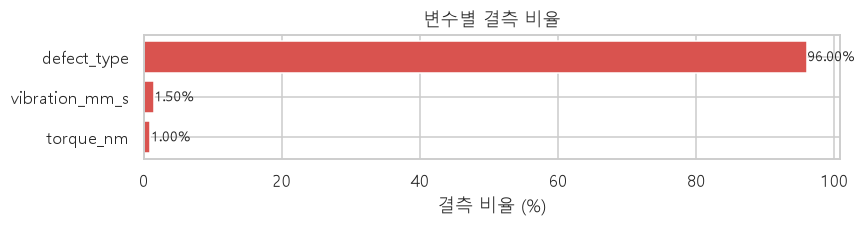

In [8]:
# =============================================================================
# [4-1] 결측값 현황 표 + 그래프
# =============================================================================
miss = pd.DataFrame({
    "결측건수": df.isna().sum(),
    "결측비율(%)": (df.isna().mean() * 100).round(2),
    "자료형": df.dtypes.astype(str),
})
miss = miss[miss["결측건수"] > 0].sort_values("결측건수", ascending=False)

if len(miss) == 0:
    print("결측값이 없습니다.")
else:
    display(miss)
    fig, ax = plt.subplots(figsize=(8, max(2.2, 0.45 * len(miss))))
    ax.barh(miss.index[::-1], miss["결측비율(%)"][::-1], color="#d9534f")
    ax.set_xlabel("결측 비율 (%)")
    ax.set_title("변수별 결측 비율")
    for i, v in enumerate(miss["결측비율(%)"][::-1]):
        ax.text(v + 0.05, i, f"{v:.2f}%", va="center", fontsize=9)
    plt.tight_layout()
    plt.show()

In [9]:
# =============================================================================
# [4-2] 결측이 '어디에 몰려 있는지' 확인 - 무작위 결측인가?
# =============================================================================
# 결측 여부(0/1)를 만들고, 주요 범주별로 결측률을 비교한다.
miss_cols = df.columns[df.isna().any()].tolist()
check_groups = ["shift", "line_id", "product_model", "equipment_id", "operator_group"]      # 이 데이터의 주요 그룹 변수

for mc in miss_cols:
    if df[mc].isna().sum() < 5:
        continue
    print(f"=== {mc} 의 결측률 (전체 {df[mc].isna().mean()*100:.2f}%) ===")
    for g in check_groups:
        if g not in df.columns or df[g].nunique() > 12:
            continue
        rate = df.groupby(g)[mc].apply(lambda s: s.isna().mean() * 100).round(2)
        print(f"  [{g}]", dict(rate))
    print()

=== torque_nm 의 결측률 (전체 1.00%) ===
  [shift] {'야간': np.float64(0.0), '주간': np.float64(1.88)}
  [line_id] {'L1': np.float64(1.23), 'L2': np.float64(0.73)}
  [product_model] {'P1': np.float64(1.23), 'P2': np.float64(0.73)}
  [equipment_id] {'M01': np.float64(2.33), 'M02': np.float64(0.67), 'M03': np.float64(0.33), 'M04': np.float64(0.67)}
  [operator_group] {'G01': np.float64(1.5), 'G02': np.float64(1.0), 'G03': np.float64(1.0), 'G04': np.float64(2.0), 'G05': np.float64(0.5), 'G06': np.float64(0.0)}

=== vibration_mm_s 의 결측률 (전체 1.50%) ===
  [shift] {'야간': np.float64(1.96), '주간': np.float64(1.09)}
  [line_id] {'L1': np.float64(1.23), 'L2': np.float64(1.82)}
  [product_model] {'P1': np.float64(1.23), 'P2': np.float64(1.82)}
  [equipment_id] {'M01': np.float64(1.33), 'M02': np.float64(1.33), 'M03': np.float64(2.0), 'M04': np.float64(1.33)}
  [operator_group] {'G01': np.float64(1.0), 'G02': np.float64(2.0), 'G03': np.float64(1.5), 'G04': np.float64(2.0), 'G05': np.float64(1.0), 'G06': np.fl

특정 그룹의 결측률이 다른 그룹보다 **2배 이상** 높다면 "무작위로 빠진 것"이
아닙니다. 그 그룹의 센서나 기록 절차에 문제가 있을 가능성이 있고, 분석 보고서에
**"데이터 수집 체계 개선 필요"** 로 적어야 하는 발견입니다.

### 4-2. 중복 점검

제조 데이터에서 중복은 두 가지로 나눠 봐야 합니다.

- **완전 중복 행**: 모든 열이 같은 행. 대개 수집 과정의 오류 → 제거 검토.
- **키 중복**: 식별자나 (시각 + 설비) 조합이 중복. **반드시 "왜 중복인가"를 확인**합니다.
  같은 시각에 여러 기록이 정상인 경우(여러 설비 동시 운전, 동시 요청 접수)도 많습니다.

시계열 그래프나 시간순 분리(train/test)를 할 때 시간 중복이 있으면 결과가 엉킵니다.

In [10]:
# =============================================================================
# [4-3] 중복 점검
# =============================================================================
print("완전 중복 행 :", df.duplicated().sum(), "건")
print("record_id 중복   :", df["record_id"].duplicated().sum(), "건  (0이어야 정상)")

# 시각 중복: 같은 시각에 몇 건씩 기록되었나
tcount = df["timestamp"].value_counts()
print("\n서로 다른 시각 수 :", tcount.size, "/ 전체", len(df), "건")
print("같은 시각에 2건 이상 기록된 시각 수 :", int((tcount > 1).sum()))
print("\n[같은 시각에 기록된 건수의 분포]")
print(tcount.value_counts().sort_index().to_string())

완전 중복 행 : 0 건
record_id 중복   : 0 건  (0이어야 정상)

서로 다른 시각 수 : 1199 / 전체 1200 건
같은 시각에 2건 이상 기록된 시각 수 : 1

[같은 시각에 기록된 건수의 분포]
count
1    1198
2       1


In [11]:
# =============================================================================
# [4-4] 물리적으로 불가능한 값 찾기 (음수 / 비율 범위)
# =============================================================================
# 규칙: 시간·수량·거리·전력·유량은 음수가 될 수 없다. 비율(%)은 0~100 이어야 한다.
print("[음수가 있는 수치형 변수]")
found = False
for c in num_all:
    neg = int((df[c] < 0).sum())
    if neg > 0:
        print(f"  {c:<34s} 음수 {neg:>4d}건  (최솟값 {df[c].min():.2f})")
        found = True
if not found:
    print("  없음")

print("\n[0~100 범위를 벗어난 '%' 변수]")
found = False
for c in num_all:
    if "pct" in c:
        bad = int(((df[c] < 0) | (df[c] > 100)).sum())
        if bad:
            print(f"  {c:<34s} 범위이탈 {bad}건")
            found = True
if not found:
    print("  없음")

[음수가 있는 수치형 변수]
  없음

[0~100 범위를 벗어난 '%' 변수]
  없음


> 여기서 찾은 문제들은 **지금 고치지 않습니다.** 1편의 목표는 "발견하고 기록하기"입니다.
> 처리 규칙은 2편 맨 앞에서 `clean_data()` 함수 하나로 고정합니다. 이렇게 하면
> **"어떤 데이터로 분석했는가"를 언제든 재현**할 수 있습니다(재현성, reproducibility).
> 엑셀에서 손으로 값을 고치면 한 달 뒤에 아무도 무엇을 고쳤는지 모릅니다.

---

## 5. 변수를 '언제 알 수 있는가'로 분류하기

이 작업이 제조 데이터 분석의 **가장 중요한 단계**입니다. 통계 지식보다 **업무 흐름 이해**가
필요한 부분이고, 그래서 현업(설비·품질·생산 담당자)과 함께 해야 합니다.

### 판단 시점: 제품이 EOL 검사대에 도착하기 직전 (조립은 끝났고 검사결과는 아직 모르는 시점)

### ① 예측시점에 쓸 수 있는 변수 (입력 후보)

| 범주형 | 수치형 |
|---|---|
| `shift`, `line_id`, `product_model`, `equipment_id`, `operator_group` | `torque_nm`, `pressure_bar`, `cycle_time_sec`, `temperature_c`, `vibration_mm_s`, `downtime_min`, `energy_kwh` |

### ② 결과변수 / 사후 생성 변수 (입력 금지 — 데이터 누출)

| 변수 | 왜 쓸 수 없는가 |
|---|---|
| `defect_type` | 불량유형. 불합격 판정이 난 뒤에 기록된다. 값이 있으면 그 제품은 이미 불합격이다 |
| `inspection_time_sec` | 검사 소요시간. 검사를 해야 생기는 값이다 |
| `rework_flag` | 재작업 여부. 불합격 이후의 조치다 |
| `rework_time_min` | 재작업시간. 불합격 이후의 조치다 |
| `final_disposition` | 최종처분(합격/재작업후합격). 사실상 정답의 복사본이다 |
| `record_id` | 단순 식별번호. 의미 있는 정보가 없고 외우기(과적합)만 유발한다 |

`timestamp`(기록시각)는 그대로 쓰지 않습니다. 날짜 자체를 모델에 넣으면
"7월 13일에 불량이 많았다"를 외우게 되어 다음 달에는 쓸 수 없습니다. 대신 **시간에서
뽑아낸 정보**(시각, 요일 등)를 쓰는 것이 일반적이며, 이 데이터에서는 이미 `shift`가
그 역할을 합니다.

### 데이터 누출(data leakage)이란

**"학습할 때는 알 수 있었지만, 실제 예측 시점에는 알 수 없는 정보"** 가 모델에 들어가는 것입니다.

비유하자면 **시험 문제지 뒤에 답이 인쇄된 상태로 공부한 것**과 같습니다.
연습할 때는 100점이 나오지만, 답이 없는 실제 시험에서는 아무것도 못 풉니다.

누출의 신호는 명확합니다. **성능이 비현실적으로 높습니다** (정확도 99%, AUC 0.99+).
현장 데이터에서 그런 성능이 나오면 기뻐하기 전에 **"혹시 답을 베꼈나"** 를 먼저 의심하세요.
실무에서 가장 흔한 실패 원인이 바로 이것입니다.

In [12]:
# =============================================================================
# [5-1] 변수 그룹을 코드로 고정해 둔다 (2·3편에서도 그대로 사용)
# =============================================================================
ID_COL = "record_id"
TIME_COL = "timestamp"
TARGET_COL = "inspection_result"
POSITIVE_LABEL = "불합격"          # 이 값을 1(양성, 찾아내고 싶은 사건)로 둔다

CAT_PRE = ["shift", "line_id", "product_model", "equipment_id", "operator_group"]      # 예측시점에 쓸 수 있는 범주형
NUM_PRE = [
    "torque_nm", "pressure_bar", "cycle_time_sec", "temperature_c", "vibration_mm_s",
    "downtime_min", "energy_kwh"
]      # 예측시점에 쓸 수 있는 수치형
LEAK_COLS = [
    "defect_type", "inspection_time_sec", "rework_flag", "rework_time_min",
    "final_disposition", "record_id"
]      # 쓰면 안 되는 결과변수(데이터 누출)

print(f"입력 후보 : 범주형 {len(CAT_PRE)}개 + 수치형 {len(NUM_PRE)}개 = {len(CAT_PRE)+len(NUM_PRE)}개")
print(f"사용 금지 : {len(LEAK_COLS)}개")

# 목표변수를 0/1로 변환한다 (1 = 불합격(추가확인 대상))
df["target"] = (df['inspection_result'] == '불합격').astype(int)
print(f"\n목표변수 target: 1(불합격(추가확인 대상)) = {int(df['target'].sum())}건, "
      f"0(합격) = {int((df['target']==0).sum())}건")

입력 후보 : 범주형 5개 + 수치형 7개 = 12개
사용 금지 : 6개

목표변수 target: 1(불합격(추가확인 대상)) = 48건, 0(합격) = 1152건


---

## 6. 목표변수 분석 — 클래스 불균형과 '정확도 착시'

목표변수(= 정답, target)는 **`inspection_result`(검사결과)** 입니다.
`불합격`을 **1(양성, positive)**, `합격`을 **0(음성, negative)** 으로 바꿔서 씁니다.

왜 불합격을 1로 둘까요? 머신러닝에서 **양성(1)은 "찾아내고 싶은 드문 사건"** 에 두는 것이
관례입니다. 그래야 Recall(불량 중 몇 %를 찾았나), Precision(경보 중 몇 %가 진짜였나) 같은
지표가 현장 언어와 맞아떨어집니다.

### 클래스 불균형(class imbalance)이 왜 문제인가

제조 현장의 "찾고 싶은 사건"은 대부분 드뭅니다. 불량률 4%, 고장률 3%, SLA 위반 5%.
**좋은 일이지만 분석에는 함정**입니다.

양성이 4%인 데이터에서 **"무조건 음성"이라고만 답하는 모델**을 생각해 봅시다.

- 정확도(Accuracy) = 96% → 숫자만 보면 훌륭한 모델
- 그런데 불량을 **단 하나도** 찾지 못한다 → 현장에서는 완전히 쓸모없다

이것을 **정확도 착시(accuracy paradox)** 라고 합니다. 그래서 불균형 데이터에서는
**Recall(놓치지 않는 비율), Precision(경보의 정확성), F1** 을 함께 봅니다.
(2편에서 지표를 직접 계산합니다.)

[목표변수 원래 값의 분포]
   합격            1152건 (96.00%)
   불합격             48건 ( 4.00%)

양성(1) 비율 : 4.00%
'전부 음성'이라고만 답하는 모델의 정확도 : 96.00%
  → 이 숫자를 넘지 못하는 모델은 의미가 없다 (이것을 '기준선/baseline'이라 부른다)


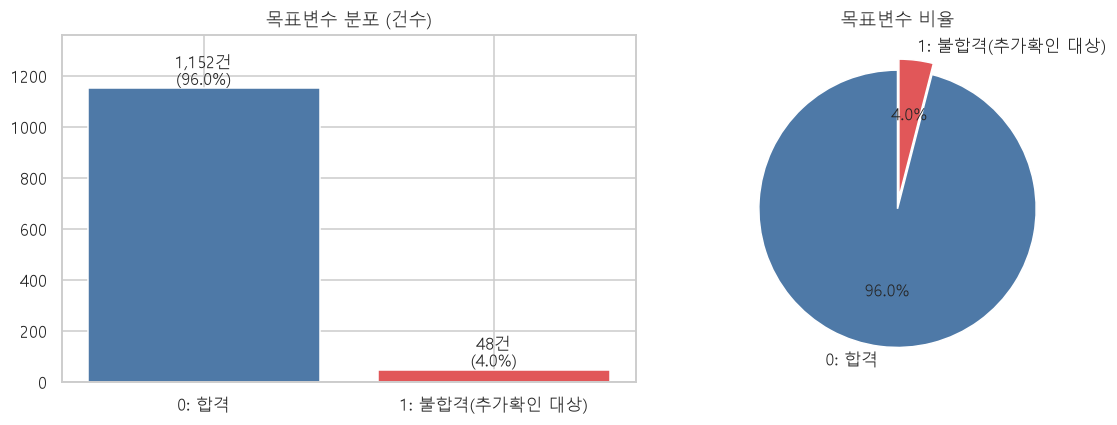

In [13]:
# =============================================================================
# [6-1] 목표변수 분포와 '아무것도 안 하는 모델'의 정확도
# =============================================================================
vc = df[TARGET_COL].value_counts(dropna=False)
print("[목표변수 원래 값의 분포]")
for k, v in vc.items():
    print(f"   {str(k):<12s} {v:>5d}건 ({v/len(df)*100:5.2f}%)")

pos_rate = df["target"].mean()
print(f"\n양성(1) 비율 : {pos_rate*100:.2f}%")
print(f"'전부 음성'이라고만 답하는 모델의 정확도 : {(1-pos_rate)*100:.2f}%")
print("  → 이 숫자를 넘지 못하는 모델은 의미가 없다 (이것을 '기준선/baseline'이라 부른다)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cnt = df["target"].value_counts().sort_index()
labels = ["0: " + "합격", "1: " + "불합격(추가확인 대상)"]
axes[0].bar(labels, cnt.values, color=["#4e79a7", "#e15759"])
for i, v in enumerate(cnt.values):
    axes[0].text(i, v, f"{v:,}건\n({v/len(df)*100:.1f}%)", ha="center", va="bottom")
axes[0].set_title("목표변수 분포 (건수)")
axes[0].set_ylim(0, max(cnt.values) * 1.18)

axes[1].pie(cnt.values, labels=labels, autopct="%1.1f%%",
            colors=["#4e79a7", "#e15759"], startangle=90, explode=(0, 0.08))
axes[1].set_title("목표변수 비율")
plt.tight_layout()
plt.show()

---

## 7. 단변량 분석 — 변수 하나씩 분포 보기

변수 하나의 분포를 볼 때 확인하는 것은 4가지입니다.

| 확인 | 의미 | 현장 해석 |
|---|---|---|
| **중심** (평균·중앙값) | 보통 어느 수준인가 | 운전 기준값과 맞는가 |
| **퍼짐** (표준편차·IQR) | 얼마나 흔들리는가 | 공정 안정성 |
| **모양** (치우침·봉우리 수) | 분포가 한쪽으로 쏠렸나, 봉우리가 2개인가 | **봉우리 2개 = 서로 다른 운전상태가 섞여 있다** |
| **꼬리** (이상치) | 극단값이 있는가 | 센서 오류인가 설비 이상인가 |

**평균과 중앙값을 함께 보세요.** 평균은 극단값에 끌려갑니다.
두 값이 크게 다르면 분포가 한쪽으로 쏠려 있다는 뜻입니다.
제조 데이터에서는 **중앙값과 P90(상위 10% 지점)** 이 평균보다 유용한 경우가 많습니다.
"보통은 이렇고, 나쁠 때는 이렇다"를 함께 말해 주기 때문입니다.

### 히스토그램과 박스플롯의 역할 분담
- **히스토그램**: 분포의 *모양*을 본다 (봉우리가 몇 개인가)
- **박스플롯**: 중심·퍼짐·이상치를 *요약*해서 본다. 그룹 비교에 특히 좋다

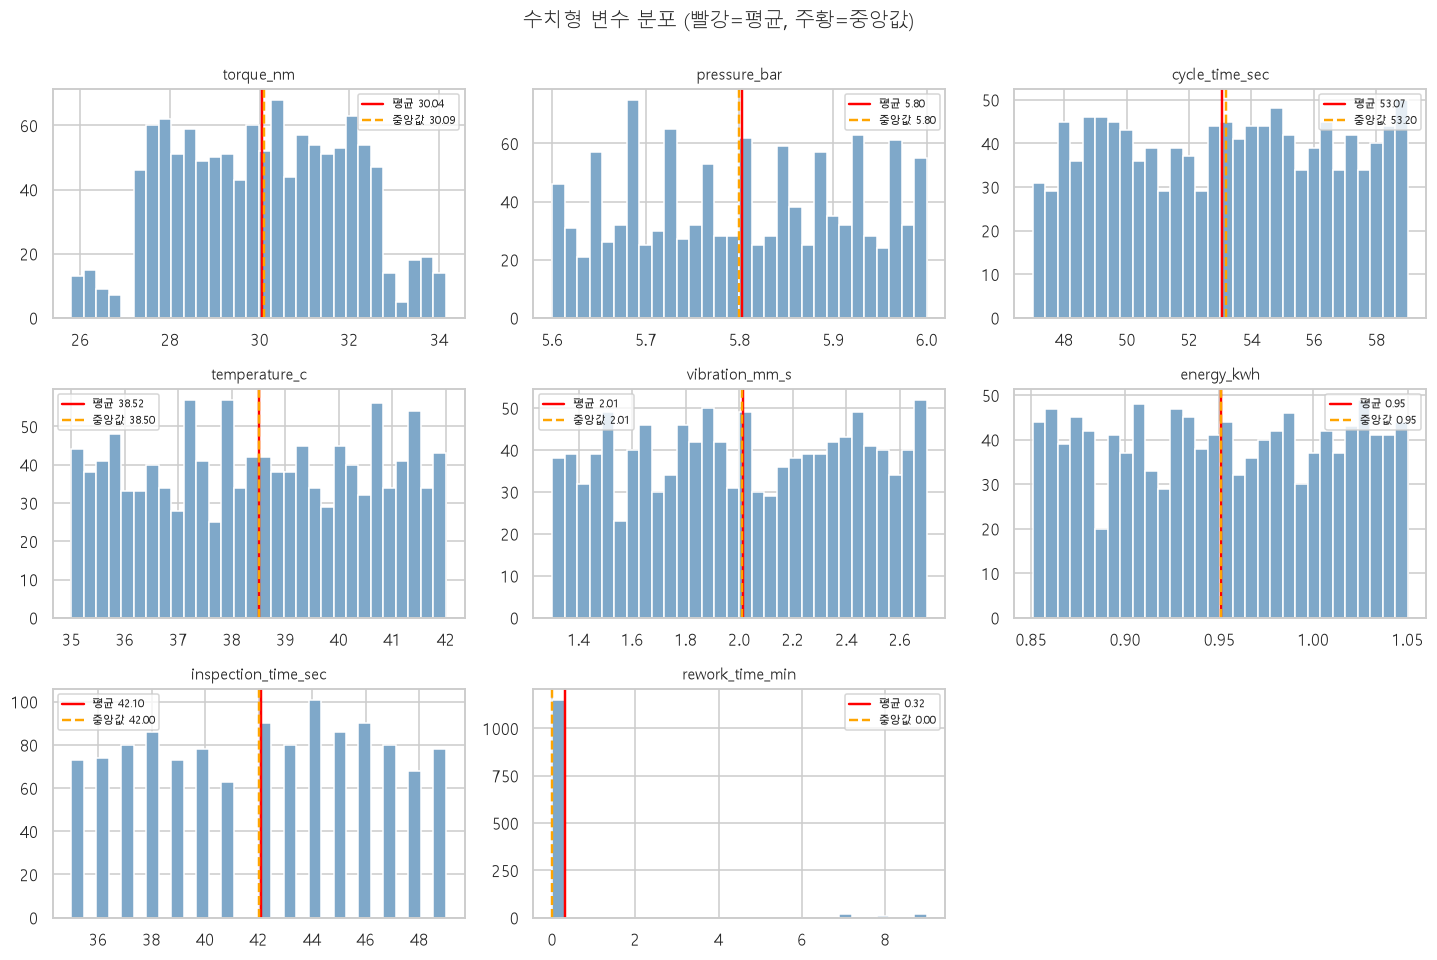

In [14]:
# =============================================================================
# [7-1] 주요 수치형 변수의 히스토그램 (분포 모양 보기)
# =============================================================================
NUM_EDA = [c for c in [
    "torque_nm", "pressure_bar", "cycle_time_sec", "temperature_c", "vibration_mm_s",
    "energy_kwh", "inspection_time_sec", "rework_time_min"
] if c in df.columns]

ncol = 3
nrow = int(np.ceil(len(NUM_EDA) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 2.9 * nrow))
axes = np.atleast_1d(axes).ravel()

for ax, c in zip(axes, NUM_EDA):
    s = df[c].dropna()
    ax.hist(s, bins=30, color="#7fa8c9", edgecolor="white")
    ax.axvline(s.mean(), color="red", ls="-", lw=1.6, label=f"평균 {s.mean():.2f}")
    ax.axvline(s.median(), color="orange", ls="--", lw=1.6, label=f"중앙값 {s.median():.2f}")
    ax.set_title(c, fontsize=10)
    ax.legend(fontsize=7)
for ax in axes[len(NUM_EDA):]:
    ax.axis("off")
fig.suptitle("수치형 변수 분포 (빨강=평균, 주황=중앙값)", y=1.00, fontsize=13)
plt.tight_layout()
plt.show()

In [15]:
# =============================================================================
# [7-2] 요약통계 + 이상치 건수 (IQR 방식)
# =============================================================================
rows = []
for c in NUM_EDA:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({
        "변수": c, "평균": s.mean(), "중앙값": s.median(), "표준편차": s.std(),
        "최소": s.min(), "P90": s.quantile(0.9), "최대": s.max(),
        "IQR이상치": int(((s < lo) | (s > hi)).sum()),
        "이상치%": round(((s < lo) | (s > hi)).mean() * 100, 1),
    })
summary = pd.DataFrame(rows).set_index("변수")
display(summary.round(3))

print("IQR 방식: 1분위-1.5×IQR 보다 작거나, 3분위+1.5×IQR 보다 큰 값을 이상치로 본다.")
print("주의: '대부분 0이고 일부만 값이 있는 이벤트성 변수'(정지시간·교체시간 등)는")
print("      0보다 큰 값 전부가 이상치로 표시된다. 이것은 오류가 아니라 '실제 사건'이다.")

,평균,중앙값,표준편차,최소,P90,최대,IQR이상치,이상치%
변수,,,,,,,,
torque_nm,30.042,30.085,1.890,25.800,32.470,34.150,0,0.000
pressure_bar,5.802,5.800,0.116,5.600,5.960,6.000,0,0.000
cycle_time_sec,53.065,53.200,3.452,47.000,57.900,59.000,0,0.000
temperature_c,38.517,38.500,2.039,35.000,41.300,42.000,0,0.000
vibration_mm_s,2.014,2.010,0.408,1.300,2.570,2.700,0,0.000
energy_kwh,0.951,0.951,0.059,0.851,1.032,1.050,0,0.000
inspection_time_sec,42.098,42.000,4.245,35.000,48.000,49.000,0,0.000
rework_time_min,0.322,0.000,1.586,0.000,0.000,9.000,48,4.000


IQR 방식: 1분위-1.5×IQR 보다 작거나, 3분위+1.5×IQR 보다 큰 값을 이상치로 본다.
주의: '대부분 0이고 일부만 값이 있는 이벤트성 변수'(정지시간·교체시간 등)는
      0보다 큰 값 전부가 이상치로 표시된다. 이것은 오류가 아니라 '실제 사건'이다.


[torque_nm]
  통계적 이상치(IQR 1.5배 기준) : 0건
  공정규격 이탈(27~33)      : 100건
  → 통계적으로는 평범해도 규격을 벗어나면 현장에서는 '문제'다. 둘은 다른 개념이다.


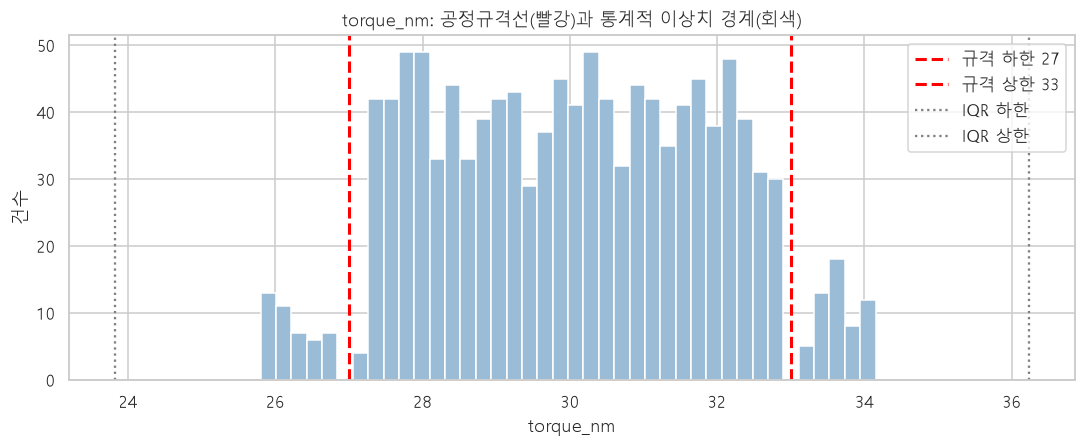

In [16]:
# -----------------------------------------------------------------------------
# [7-3] 통계적 이상치 vs 공정규격 이탈 - 체결토크 교육용 관리규격 27~33 N·m
# -----------------------------------------------------------------------------
col, LO, HI = "torque_nm", 27, 33
s = df[col].dropna()
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
stat_out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
spec_out = ((s < LO) | (s > HI)).sum()

print(f"[{col}]")
print(f"  통계적 이상치(IQR 1.5배 기준) : {stat_out}건")
print(f"  공정규격 이탈({LO}~{HI})      : {spec_out}건")
print("  → 통계적으로는 평범해도 규격을 벗어나면 현장에서는 '문제'다. 둘은 다른 개념이다.")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(s, bins=40, color="#9bbcd6", edgecolor="white")
ax.axvline(LO, color="red", ls="--", lw=2, label=f"규격 하한 {LO}")
ax.axvline(HI, color="red", ls="--", lw=2, label=f"규격 상한 {HI}")
ax.axvline(q1 - 1.5 * iqr, color="gray", ls=":", lw=1.5, label="IQR 하한")
ax.axvline(q3 + 1.5 * iqr, color="gray", ls=":", lw=1.5, label="IQR 상한")
ax.set_title(f"{col}: 공정규격선(빨강)과 통계적 이상치 경계(회색)")
ax.set_xlabel(col)
ax.set_ylabel("건수")
ax.legend()
plt.tight_layout()
plt.show()

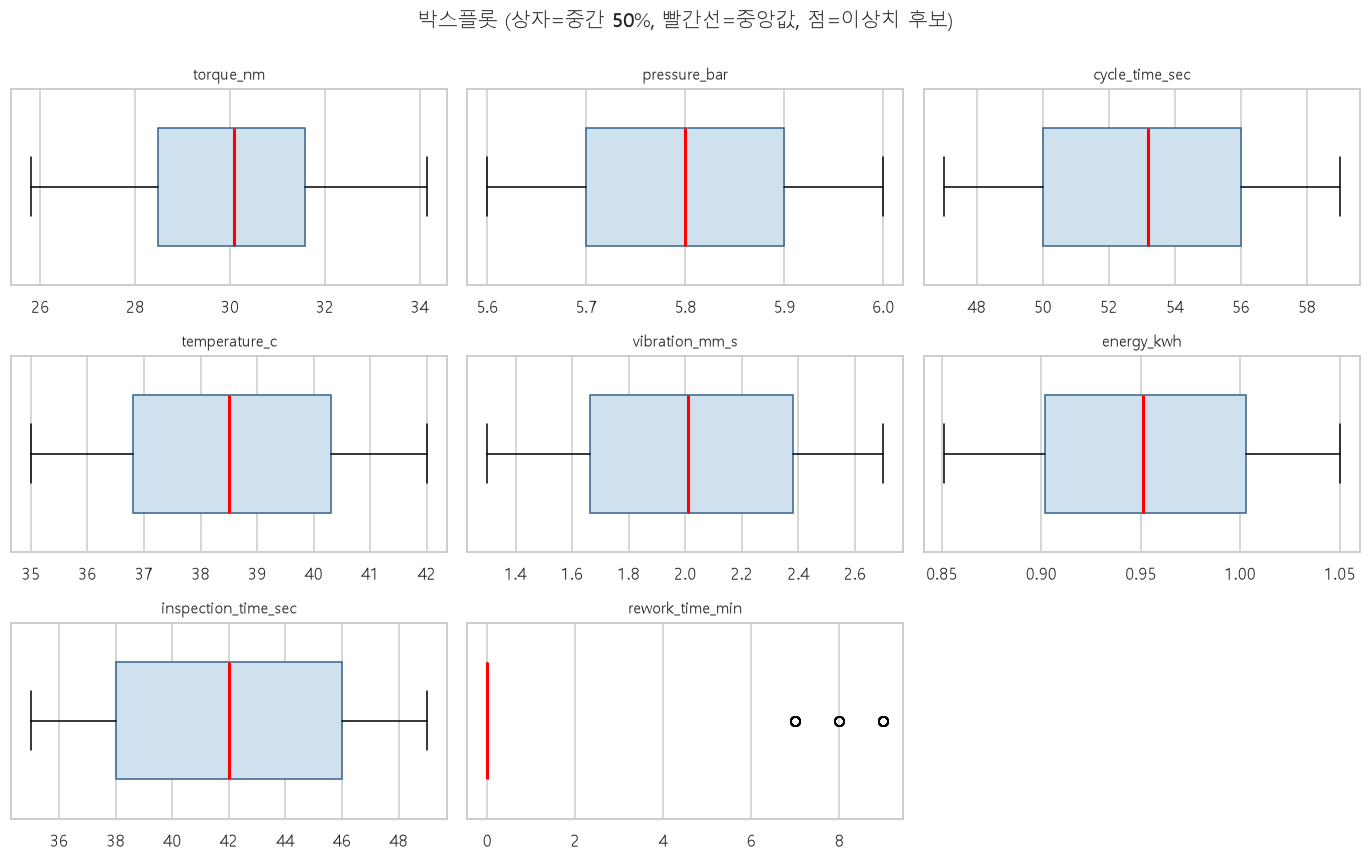

In [17]:
# =============================================================================
# [7-4] 박스플롯 - 중심/퍼짐/이상치를 한눈에
# =============================================================================
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 2.6 * nrow))
axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, NUM_EDA):
    ax.boxplot(df[c].dropna(), vert=False, widths=0.6,
               patch_artist=True,
               boxprops=dict(facecolor="#cfe0ee", edgecolor="#36648b"),
               medianprops=dict(color="red", lw=2))
    ax.set_title(c, fontsize=10)
    ax.set_yticks([])
for ax in axes[len(NUM_EDA):]:
    ax.axis("off")
fig.suptitle("박스플롯 (상자=중간 50%, 빨간선=중앙값, 점=이상치 후보)", y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

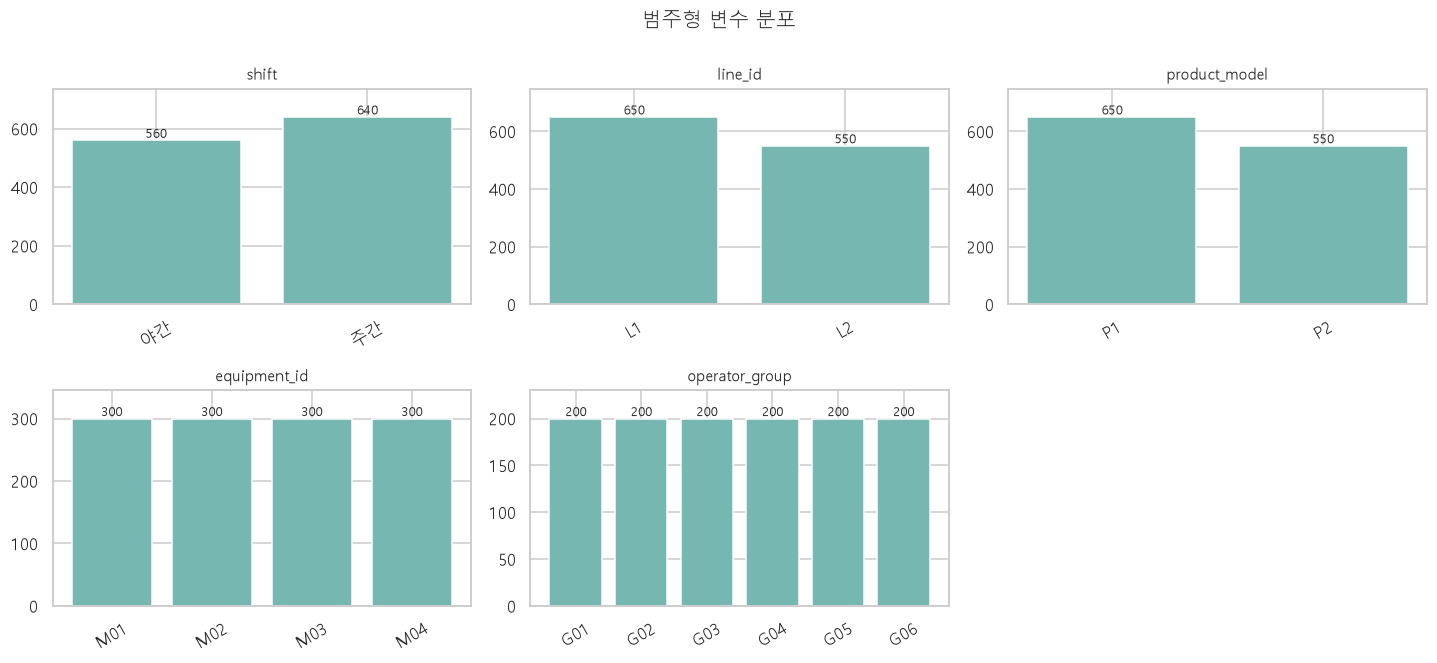

In [18]:
# =============================================================================
# [7-5] 범주형 변수의 분포 (막대그래프)
# =============================================================================
CAT_EDA = [c for c in [
    "shift", "line_id", "product_model", "equipment_id", "operator_group"
] if c in df.columns and df[c].nunique() <= 12]

ncol2 = 3
nrow2 = int(np.ceil(len(CAT_EDA) / ncol2))
fig, axes = plt.subplots(nrow2, ncol2, figsize=(4.4 * ncol2, 3.0 * nrow2))
axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, CAT_EDA):
    vc = df[c].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color="#76b7b2")
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v}", ha="center", va="bottom", fontsize=8)
    ax.set_title(c, fontsize=10)
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylim(0, vc.values.max() * 1.15)
for ax in axes[len(CAT_EDA):]:
    ax.axis("off")
fig.suptitle("범주형 변수 분포", y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

---

## 8. 그룹 비교 — "어느 조건에서 문제가 많은가"

여기서부터가 **현장 보고에 바로 쓰이는 분석**입니다. 방법은 간단합니다.
**범주형 변수로 데이터를 나누고, 그룹별 양성률(불량률·고장률·위반률)을 비교**합니다.

### 반드시 '표본 수'를 함께 보세요

그룹별 비율만 보면 큰 실수를 합니다.

| 그룹 | 양성 | 전체 | 비율 |
|---|---|---|---|
| X | 2 | 10 | **20.0%** |
| Y | 40 | 400 | 10.0% |

X의 비율이 2배 높지만, X는 **10건 중 2건**입니다. 한 건만 달라도 비율이 10%p 움직입니다.
이렇게 표본이 적은 그룹의 비율은 **신뢰할 수 없습니다.**
현장 보고에서는 항상 **"n건 중 m건(x%)"** 형식으로 적으세요.

> 참고: 표본이 적을 때의 불확실성은 통계적으로 **신뢰구간**으로 표현합니다.
> 7~9회차(통계검증)에서 비율 차이의 유의성 검정(카이제곱 검정 등)을 배웁니다.
> 1편에서는 **"표본 수를 함께 본다"** 는 습관만 확실히 익히세요.

In [19]:
# =============================================================================
# [8-1] 그룹별 양성률 계산 함수 (앞으로 계속 사용)
# =============================================================================
def group_target_rate(col, data=None, sort_by_rate=True, min_n=0):
    """범주형 변수 col 기준으로 그룹별 건수 / 양성 건수 / 양성률을 표로 만든다."""
    d = df if data is None else data
    g = d.groupby(col, dropna=False)["target"]
    out = pd.DataFrame({
        "전체건수": g.size(),
        "양성건수": g.sum().astype(int),
    })
    out["양성률(%)"] = (out["양성건수"] / out["전체건수"] * 100).round(2)
    out = out[out["전체건수"] >= min_n]
    return out.sort_values("양성률(%)", ascending=False) if sort_by_rate else out.sort_index()


def plot_group_rate(col, data=None, ax=None):
    """그룹별 양성률 막대그래프 + 막대 위에 'n건 중 m건' 표기."""
    t = group_target_rate(col, data=data, sort_by_rate=False)
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(min(11, 1.6 * len(t) + 3), 3.6))
    overall = (df if data is None else data)["target"].mean() * 100
    ax.bar(t.index.astype(str), t["양성률(%)"], color="#e15759")
    ax.axhline(overall, color="gray", ls="--", lw=1.4,
               label=f"전체 평균 {overall:.2f}%")
    for i, (n, m, r) in enumerate(zip(t["전체건수"], t["양성건수"], t["양성률(%)"])):
        ax.text(i, r, f"{r:.1f}%\n({m}/{n})", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"{col} 별 양성률")
    ax.set_ylabel("양성률 (%)")
    ax.set_ylim(0, max(t["양성률(%)"].max() * 1.35, overall * 1.5, 1))
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)
    if own_fig:
        plt.tight_layout()
        plt.show()
    return t


print("함수 2개 준비 완료: group_target_rate(열이름), plot_group_rate(열이름)")

함수 2개 준비 완료: group_target_rate(열이름), plot_group_rate(열이름)


In [20]:
# =============================================================================
# [8-2] 주요 범주형 변수별 양성률 표
# =============================================================================
GROUP_COLS = [c for c in ["shift", "line_id", "product_model", "equipment_id", "operator_group"] if c in df.columns]

for g in GROUP_COLS:
    print(f"\n===== {g} 별 불합격(추가확인 대상) 비율 =====")
    display(group_target_rate(g))


===== shift 별 불합격(추가확인 대상) 비율 =====


,전체건수,양성건수,양성률(%)
shift,,,
야간,560,30,5.360
주간,640,18,2.810



===== line_id 별 불합격(추가확인 대상) 비율 =====


,전체건수,양성건수,양성률(%)
line_id,,,
L2,550,28,5.090
L1,650,20,3.080



===== product_model 별 불합격(추가확인 대상) 비율 =====


,전체건수,양성건수,양성률(%)
product_model,,,
P2,550,28,5.090
P1,650,20,3.080



===== equipment_id 별 불합격(추가확인 대상) 비율 =====


,전체건수,양성건수,양성률(%)
equipment_id,,,
M03,300,22,7.330
M02,300,9,3.000
M04,300,9,3.000
M01,300,8,2.670



===== operator_group 별 불합격(추가확인 대상) 비율 =====


,전체건수,양성건수,양성률(%)
operator_group,,,
G05,200,12,6.000
G04,200,10,5.000
G01,200,9,4.500
G02,200,8,4.000
G06,200,5,2.500
G03,200,4,2.000


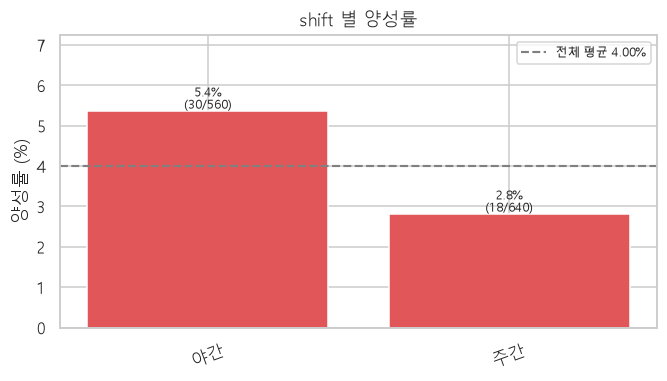

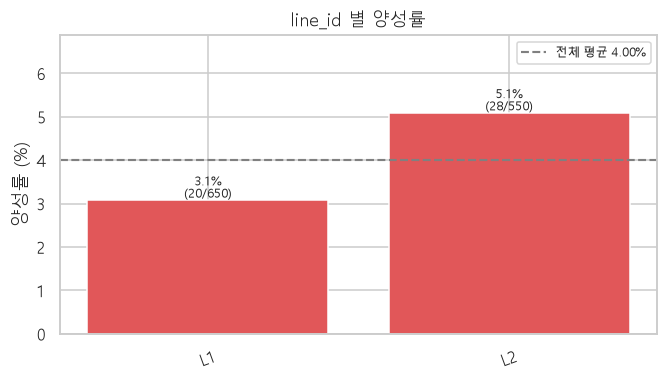

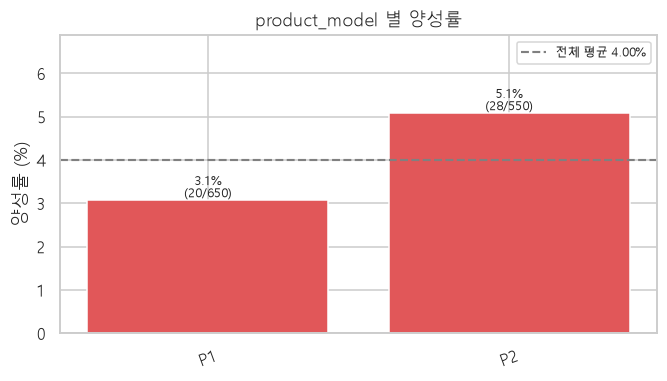

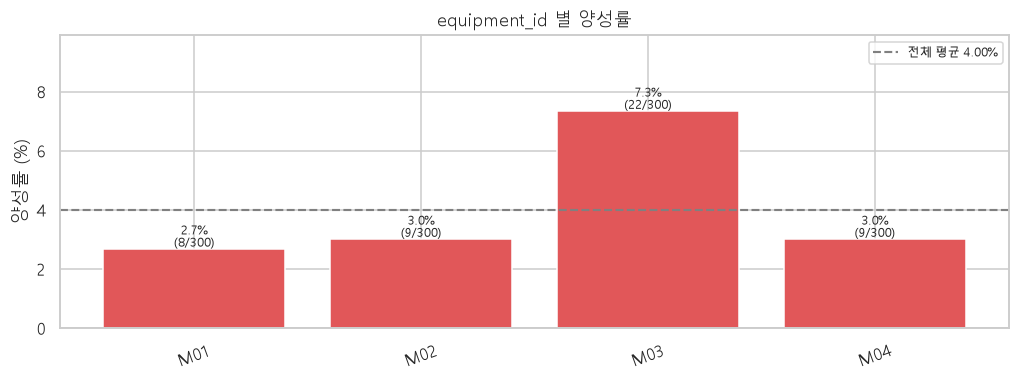

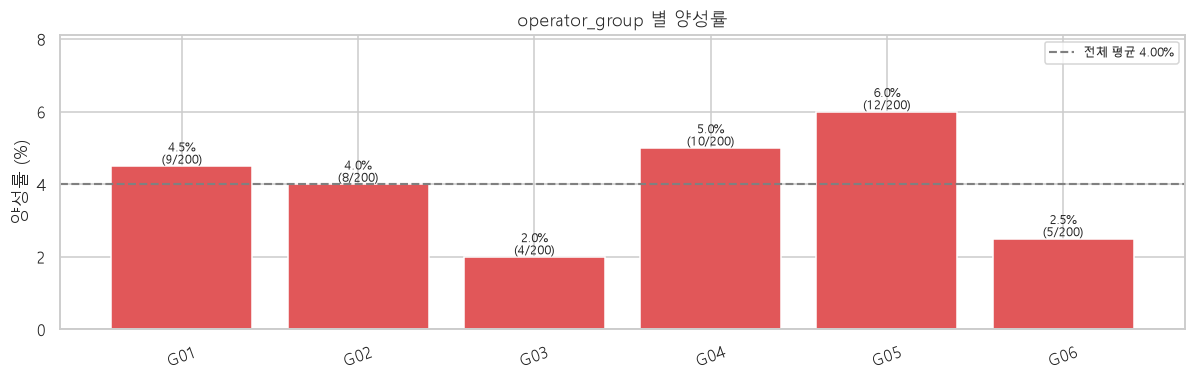

In [21]:
# =============================================================================
# [8-3] 그룹별 양성률 그래프 (전체 평균선과 비교)
# =============================================================================
for g in GROUP_COLS:
    plot_group_rate(g)

### 수치형 변수를 양성/음성으로 나눠 비교하기

범주형은 "그룹별 양성률"로 비교했습니다. 수치형은 반대로
**"양성 집단과 음성 집단의 값 분포가 다른가"** 를 봅니다.

차이를 볼 때 **평균 차이만 보면 안 됩니다.** 두 집단의 퍼짐(표준편차)이 크면
평균이 조금 달라도 실제로는 거의 구분되지 않습니다. 그래서 **표준화된 차이**
(Cohen's d = 평균 차이 ÷ 공통 표준편차)를 함께 봅니다.

| Cohen's d | 해석 |
|---|---|
| 0.2 미만 | 거의 차이 없음 — 단독 신호로 쓸 수 없다 |
| 0.2 ~ 0.5 | 작은 차이 |
| 0.5 ~ 0.8 | 중간 차이 |
| 0.8 이상 | 큰 차이 — 유력한 신호 |

제조 데이터에서 d가 0.8을 넘는 단일 변수는 드뭅니다. **대부분 0.1~0.4 수준**이고,
그래서 **여러 변수를 조합하는 머신러닝**이 필요합니다.

In [22]:
# =============================================================================
# [8-4] 양성/음성 집단의 수치형 변수 비교 (평균 차이 + Cohen's d)
# =============================================================================
rows = []
for c in NUM_EDA:
    a = df.loc[df["target"] == 1, c].dropna()   # 양성 집단
    b = df.loc[df["target"] == 0, c].dropna()   # 음성 집단
    if len(a) < 3 or len(b) < 3:
        continue
    # 공통 표준편차(pooled std)로 평균 차이를 표준화한다
    sp = np.sqrt(((len(a) - 1) * a.std() ** 2 + (len(b) - 1) * b.std() ** 2)
                 / (len(a) + len(b) - 2))
    d_val = (a.mean() - b.mean()) / sp if sp > 0 else 0.0
    rows.append({"변수": c, "양성평균": a.mean(), "음성평균": b.mean(),
                 "차이": a.mean() - b.mean(), "Cohen_d": d_val,
                 "절대값_d": abs(d_val)})

cmp = pd.DataFrame(rows).sort_values("절대값_d", ascending=False).set_index("변수")
display(cmp.drop(columns="절대값_d").round(3))

print("Cohen's d 해석: |d|<0.2 거의 차이없음 / 0.2~0.5 작음 / 0.5~0.8 중간 / >0.8 큼")
print("→ 상위에 올라온 변수가 '불량·고장 신호 후보'다. 다만 인과관계의 증거는 아니다.")

,양성평균,음성평균,차이,Cohen_d
변수,,,,
rework_time_min,8.042,0.000,8.042,45.202
energy_kwh,0.931,0.952,-0.022,-0.368
temperature_c,39.031,38.495,0.536,0.263
vibration_mm_s,2.077,2.012,0.065,0.160
torque_nm,30.222,30.034,0.188,0.100
cycle_time_sec,52.942,53.070,-0.129,-0.037
pressure_bar,5.805,5.802,0.003,0.022
inspection_time_sec,42.021,42.101,-0.080,-0.019


Cohen's d 해석: |d|<0.2 거의 차이없음 / 0.2~0.5 작음 / 0.5~0.8 중간 / >0.8 큼
→ 상위에 올라온 변수가 '불량·고장 신호 후보'다. 다만 인과관계의 증거는 아니다.


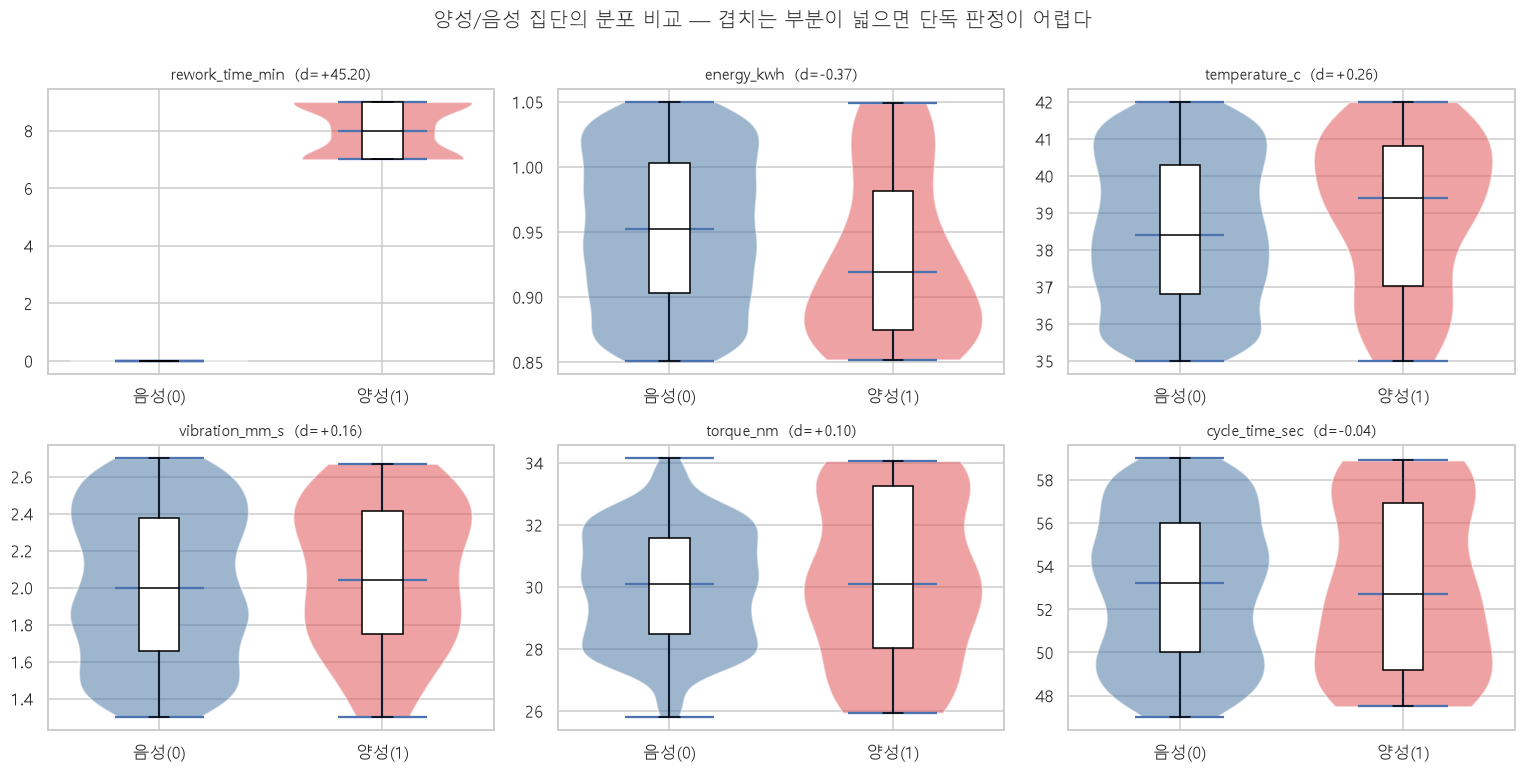

In [23]:
# =============================================================================
# [8-5] 상위 6개 변수의 양성/음성 분포 비교 (박스플롯 + 바이올린)
# =============================================================================
top_vars = cmp.head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()
for ax, c in zip(axes, top_vars):
    data = [df.loc[df["target"] == 0, c].dropna(), df.loc[df["target"] == 1, c].dropna()]
    parts = ax.violinplot(data, positions=[0, 1], showmedians=True, widths=0.8)
    for pc, color in zip(parts["bodies"], ["#4e79a7", "#e15759"]):
        pc.set_facecolor(color)
        pc.set_alpha(0.55)
    bp = ax.boxplot(data, positions=[0, 1], widths=0.18, patch_artist=True,
                    boxprops=dict(facecolor="white"), medianprops=dict(color="black"))
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["음성(0)", "양성(1)"])
    ax.set_title(f"{c}  (d={cmp.loc[c,'Cohen_d']:+.2f})", fontsize=10)
for ax in axes[len(top_vars):]:
    ax.axis("off")
fig.suptitle("양성/음성 집단의 분포 비교 — 겹치는 부분이 넓으면 단독 판정이 어렵다", y=1.0)
plt.tight_layout()
plt.show()

---

## 9. 교차분석 — 두 조건을 겹쳐서 보기 (교란 찾기)

그룹을 **하나씩** 볼 때 보이는 차이는 **다른 변수 때문일 수 있습니다.**
이것이 **교란(confounding)** 이고, 데이터 분석에서 가장 자주 발생하는 오류의 원인입니다.

### 고전적인 예: 심슨의 역설(Simpson's paradox)

어떤 병원 A의 수술 성공률이 병원 B보다 낮게 나왔습니다. 그런데 환자를
**중증/경증으로 나눠 보면** 두 집단 모두에서 A가 더 높았습니다.
A가 중증 환자를 훨씬 많이 받았기 때문입니다.
**전체 숫자만 보면 결론이 뒤집힙니다.**

제조 현장에서도 똑같습니다. "야간조 불량률이 높다"는 야간에 만든 **제품·설비 구성**
때문일 수 있고, "C03 압축기가 문제"는 C03이 맡은 **부하 조건** 때문일 수 있습니다.

### 교차표(pivot table)로 확인하는 방법
`shift` × `equipment_id` 로 나눠 각 칸의 양성률과 건수를 함께 봅니다.
칸의 건수가 적으면(10건 미만) 그 칸의 비율은 참고만 합니다.

[칸별 건수]


equipment_id,M01,M02,M03,M04
shift,,,,
야간,121,119,140,180
주간,179,181,160,120


[칸별 양성률 %]


equipment_id,M01,M02,M03,M04
shift,,,,
야간,6.600,0.000,10.700,3.900
주간,0.000,5.000,4.400,1.700


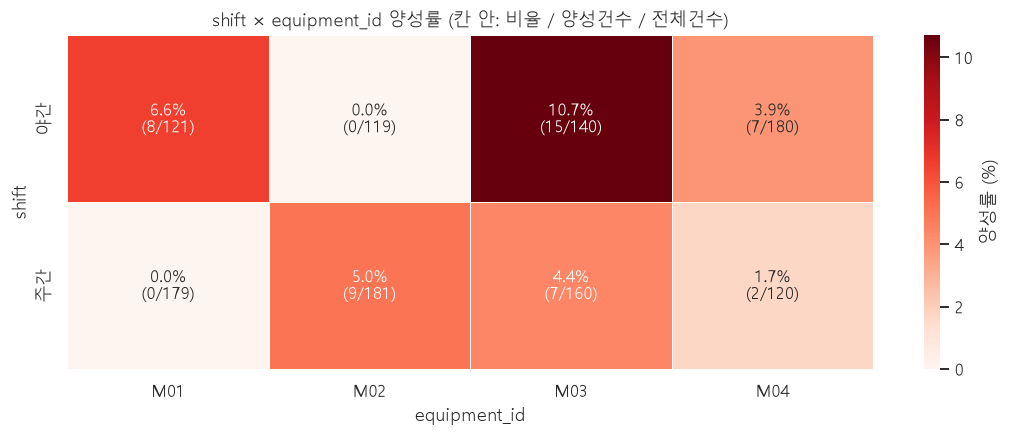

In [24]:
# =============================================================================
# [9-1] 두 변수 교차 양성률 (히트맵)
# =============================================================================
GX, GY = "shift", "equipment_id"

cnt = pd.crosstab(df[GX], df[GY])                                   # 칸별 건수
pos = pd.crosstab(df[GX], df[GY], values=df["target"], aggfunc="sum").fillna(0)
rate = (pos / cnt * 100).round(1)                                   # 칸별 양성률(%)

print("[칸별 건수]")
display(cnt)
print("[칸별 양성률 %]")
display(rate)

fig, ax = plt.subplots(figsize=(1.5 * cnt.shape[1] + 4, 0.8 * cnt.shape[0] + 2.5))
annot = (rate.astype(str) + "%\n(" + pos.astype(int).astype(str) + "/"
         + cnt.astype(str) + ")")
sns.heatmap(rate, annot=annot, fmt="", cmap="Reds", ax=ax,
            cbar_kws={"label": "양성률 (%)"}, linewidths=0.5, linecolor="white")
ax.set_title(f"{GX} × {GY} 양성률 (칸 안: 비율 / 양성건수 / 전체건수)")
plt.tight_layout()
plt.show()

In [25]:
# =============================================================================
# [9-2] 심슨의 역설 점검 - 하나씩 볼 때와 겹쳐 볼 때가 다른가?
# =============================================================================
print(f"① {GX} 만 볼 때")
display(group_target_rate(GX, sort_by_rate=False))
print(f"② {GY} 만 볼 때")
display(group_target_rate(GY, sort_by_rate=False))
print(f"③ {GX} × {GY} 를 함께 볼 때 (위 히트맵)")
print("   → ①②에서 보인 차이가 ③에서도 유지되는지 확인한다.")
print("   → 특정 조합에만 몰려 있다면, '단일 변수 때문'이라는 결론은 틀렸을 가능성이 높다.")

# 조합 중 양성률이 가장 높은 칸 Top 5 (건수 10건 이상만)
combo = (df.groupby([GX, GY])["target"].agg(["size", "sum", "mean"])
           .rename(columns={"size": "전체", "sum": "양성", "mean": "양성률"}))
combo["양성률"] = (combo["양성률"] * 100).round(2)
combo = combo[combo["전체"] >= 10].sort_values("양성률", ascending=False)
print("\n[위험조합 Top 5 (10건 이상인 칸만)]")
display(combo.head(5))

① shift 만 볼 때


,전체건수,양성건수,양성률(%)
shift,,,
야간,560,30,5.360
주간,640,18,2.810


② equipment_id 만 볼 때


,전체건수,양성건수,양성률(%)
equipment_id,,,
M01,300,8,2.670
M02,300,9,3.000
M03,300,22,7.330
M04,300,9,3.000


③ shift × equipment_id 를 함께 볼 때 (위 히트맵)
   → ①②에서 보인 차이가 ③에서도 유지되는지 확인한다.
   → 특정 조합에만 몰려 있다면, '단일 변수 때문'이라는 결론은 틀렸을 가능성이 높다.

[위험조합 Top 5 (10건 이상인 칸만)]


전체  양성    양성률
shift equipment_id                
야간    M03           140  15 10.710
      M01           121   8  6.610
주간    M02           181   9  4.970
      M03           160   7  4.380
야간    M04           180   7  3.890

### 이 데이터에 일부러 심어둔 함정 3개

**① 라인과 제품모델이 완전히 겹칩니다 (교란, confounding)**
`L1`에서는 `P1`만, `L2`에서는 `P2`만 생산했습니다. 따라서 "L2가 문제다"와 "P2가 문제다"를
**이 데이터만으로는 절대 구분할 수 없습니다.** 교차표를 그려 보면 대각선만 채워진
모양이 나옵니다. 이런 구조를 발견하면 분석이 끝난 게 아니라, **"라인을 바꿔 P2를
생산해 보는 실험"** 을 현장에 요청해야 한다는 뜻입니다.

**② 야간조라는 꼬리표 안에 설비 구성이 숨어 있습니다**
야간 + M03 조합은 140건 중 15건(10.7%)이 불합격입니다. 그 외 조건은 1,060건 중
33건(3.1%)입니다. "야간이 문제"라기보다 **"야간에 많이 돌린 M03"** 이 더 설명력이 높습니다.
이것을 확인하지 않고 야간조 교육을 강화하면 비용만 쓰고 불량은 줄지 않습니다.

**③ 작업그룹별 불량률 차이는 사람의 능력 차이가 아닙니다**
G01~G06의 불량률은 2.0%~6.0%로 차이가 납니다. 하지만 각 그룹이 담당한 제품·설비·근무조
구성이 다릅니다. **이 변수는 작업자 평가용이 아니라 "그룹별 공정조건 차이"를 찾는
단서로만** 사용합니다. 사람에 대한 결론은 데이터 분석의 범위를 넘습니다.

---

## 10. 상관분석과 산점도 — 변수 사이의 관계

### 상관계수(correlation)란
두 수치형 변수가 **함께 커지고 함께 작아지는 정도**를 -1 ~ +1 사이 숫자로 나타낸 값입니다.

| 값 | 의미 |
|---|---|
| +1 에 가까움 | 한쪽이 커지면 다른 쪽도 커진다 (양의 상관) |
| 0 에 가까움 | 직선 관계가 없다 |
| -1 에 가까움 | 한쪽이 커지면 다른 쪽은 작아진다 (음의 상관) |

**상관계수의 3가지 한계를 꼭 기억하세요.**

1. **직선 관계만 봅니다.** U자 모양(최적점이 있는 관계)이면 상관계수가 0으로 나옵니다.
   공정에서는 "너무 낮아도 문제, 너무 높아도 문제"인 변수가 많습니다. → **산점도를 꼭 함께 보세요.**
2. **상관 ≠ 인과.** 아이스크림 판매량과 익사 사고는 강한 양의 상관이 있습니다.
   원인은 둘 다 **여름**이기 때문입니다. 이것을 **공통 원인(confounder)** 이라고 합니다.
3. **이상치에 민감합니다.** 극단값 몇 개가 상관계수를 크게 바꿉니다.

### 상관분석을 쓰는 실무적 이유 2가지
- **목표변수와의 관계 탐색**: 어떤 변수가 불량·고장과 함께 움직이는가 (신호 후보)
- **변수끼리의 중복 확인**: 두 변수의 상관이 0.9 이상이면 **같은 정보**입니다
  (다중공선성). 모델에 둘 다 넣으면 해석이 불안정해집니다. → 3편에서 다룹니다.

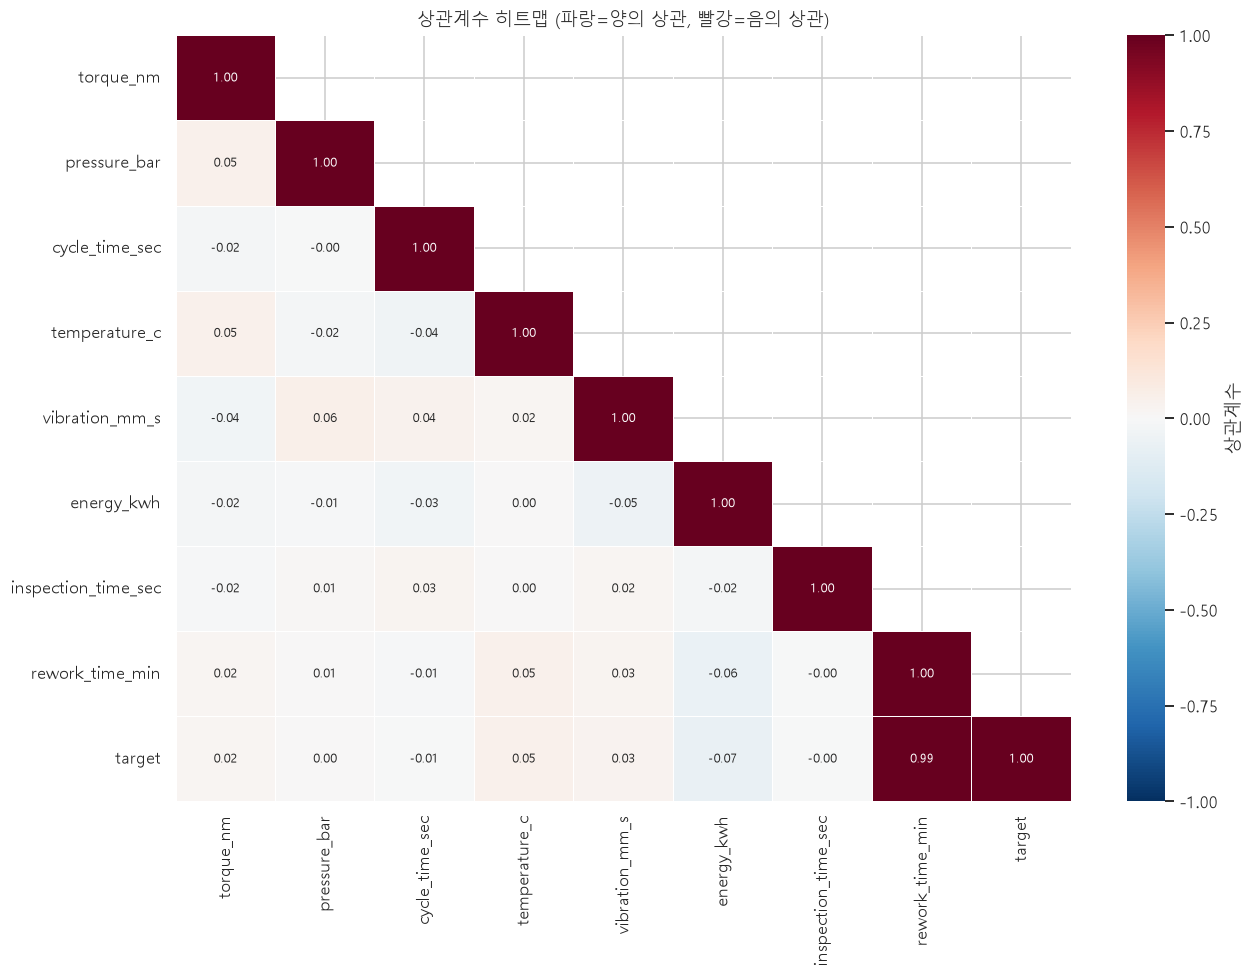

In [26]:
# =============================================================================
# [10-1] 상관계수 히트맵 (수치형 변수 + 목표변수)
# =============================================================================
corr_cols = NUM_EDA + ["target"]
corr = df[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(1.0 * len(corr_cols) + 3, 0.78 * len(corr_cols) + 2))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)       # 위쪽 삼각형은 가린다(중복)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, ax=ax, linewidths=0.4, annot_kws={"size": 8},
            cbar_kws={"label": "상관계수"})
ax.set_title("상관계수 히트맵 (파랑=양의 상관, 빨강=음의 상관)")
plt.tight_layout()
plt.show()

,상관계수,절대값
rework_time_min,0.994,0.994
energy_kwh,-0.072,0.072
temperature_c,0.052,0.052
vibration_mm_s,0.031,0.031
torque_nm,0.020,0.020
cycle_time_sec,-0.007,0.007
pressure_bar,0.004,0.004
inspection_time_sec,-0.004,0.004


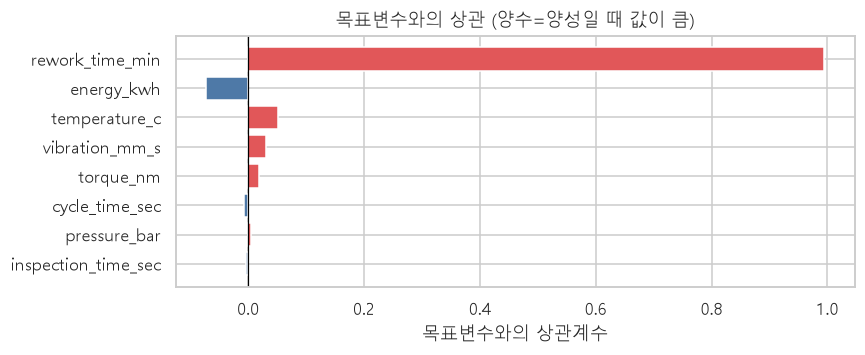

주의 1: 상관이 크다고 원인은 아니다.
주의 2: 상관이 0에 가까워도 '구간별로는 관계가 있는' 경우가 있다(비선형). 산점도로 확인!
주의 3: 결과변수(사후 생성)가 상위에 있으면 당연한 결과다. 모델 입력에서는 제외한다.


In [27]:
# =============================================================================
# [10-2] 목표변수와 상관이 큰 변수 순위
# =============================================================================
tc = corr["target"].drop("target").sort_values(key=np.abs, ascending=False)
tbl = pd.DataFrame({"상관계수": tc.round(3), "절대값": tc.abs().round(3)})
display(tbl)

fig, ax = plt.subplots(figsize=(8, max(2.5, 0.42 * len(tc))))
colors = ["#e15759" if v > 0 else "#4e79a7" for v in tc.values[::-1]]
ax.barh(tc.index[::-1], tc.values[::-1], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("목표변수와의 상관계수")
ax.set_title("목표변수와의 상관 (양수=양성일 때 값이 큼)")
plt.tight_layout()
plt.show()

print("주의 1: 상관이 크다고 원인은 아니다.")
print("주의 2: 상관이 0에 가까워도 '구간별로는 관계가 있는' 경우가 있다(비선형). 산점도로 확인!")
print("주의 3: 결과변수(사후 생성)가 상위에 있으면 당연한 결과다. 모델 입력에서는 제외한다.")

### 산점도(scatter plot) — EDA에서 가장 많은 것을 알려 주는 그림

산점도는 점 하나가 **기록 하나**입니다. 두 변수를 축에 놓고, 점의 색으로 양성/음성을
구분하면 **"어느 영역에 문제가 모여 있는가"** 가 눈에 보입니다.

이 그림에서 읽을 것:
1. **모양** — 직선인가, 곡선인가, 흩어졌는가
2. **군집** — 점이 여러 덩어리로 나뉘는가 (= 운전상태가 여러 개)
3. **색의 분포** — 양성(빨강)이 특정 영역에 모여 있는가 → **판정규칙의 후보**
4. **동떨어진 점** — 추세선에서 멀리 벗어난 점 = 이상 사례 (개별 확인 대상)

이번에 볼 조합:
- `torque_nm` vs `temperature_c` — 체결토크와 설비온도를 함께 보면 불합격이 특정 영역에 모여 있는지 알 수 있다
- `cycle_time_sec` vs `vibration_mm_s` — 사이클타임이 길어질 때 진동이 함께 커지는지 확인한다
- `torque_nm` vs `cycle_time_sec` — 두 공정조건의 조합으로 불합격이 구분되는지 확인한다

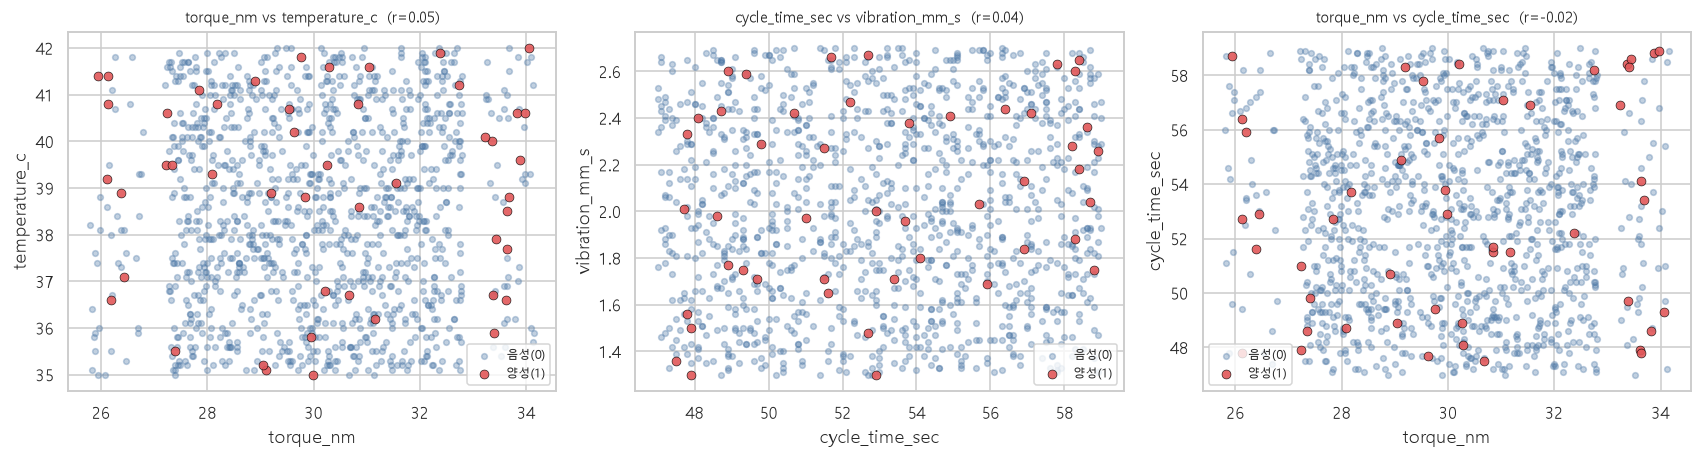

In [28]:
# =============================================================================
# [10-3] 산점도 (색 = 양성/음성)
# =============================================================================
PAIRS = [
    ("torque_nm", "temperature_c"),
    ("cycle_time_sec", "vibration_mm_s"),
    ("torque_nm", "cycle_time_sec")
]
PAIRS = [(x, y) for x, y in PAIRS if x in df.columns and y in df.columns]

fig, axes = plt.subplots(1, len(PAIRS), figsize=(5.2 * len(PAIRS), 4.3))
axes = np.atleast_1d(axes).ravel()
for ax, (x, y) in zip(axes, PAIRS):
    neg = df[df["target"] == 0]
    pos = df[df["target"] == 1]
    ax.scatter(neg[x], neg[y], s=14, alpha=0.35, c="#4e79a7", label="음성(0)")
    ax.scatter(pos[x], pos[y], s=34, alpha=0.9, c="#e15759",
               edgecolors="black", linewidths=0.4, label="양성(1)")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    r = df[[x, y]].corr().iloc[0, 1]
    ax.set_title(f"{x} vs {y}  (r={r:.2f})", fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

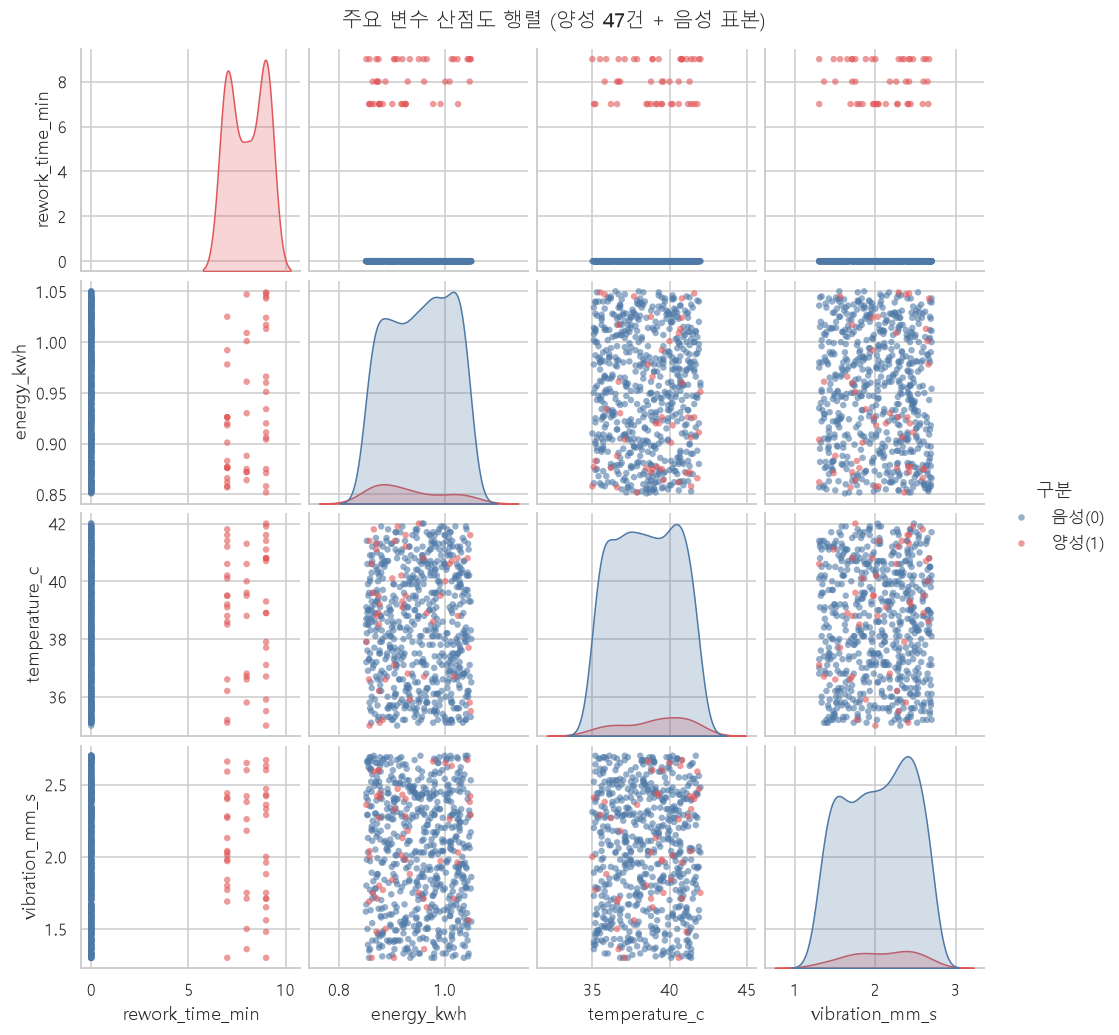

In [29]:
# =============================================================================
# [10-4] 산점도 행렬(pairplot) - 상위 4개 변수를 서로 다 비교
# =============================================================================
# 양성 사례가 적으면 점이 가려지므로, 음성은 일부만 뽑아 그린다(시각적 균형)
top4 = [c for c in cmp.head(4).index.tolist() if c in df.columns]
plot_df = df[top4 + ["target"]].dropna().copy()
plot_df["구분"] = plot_df["target"].map({0: "음성(0)", 1: "양성(1)"})

n_pos = int((plot_df["target"] == 1).sum())
sample_neg = plot_df[plot_df["target"] == 0].sample(
    min(600, int((plot_df["target"] == 0).sum())), random_state=42)
plot_df2 = pd.concat([sample_neg, plot_df[plot_df["target"] == 1]])

g = sns.pairplot(plot_df2, vars=top4, hue="구분",
                 palette={"음성(0)": "#4e79a7", "양성(1)": "#e15759"},
                 plot_kws=dict(s=18, alpha=0.6, edgecolor="none"),
                 diag_kind="kde", height=2.3)
g.figure.suptitle(f"주요 변수 산점도 행렬 (양성 {n_pos}건 + 음성 표본)", y=1.02)
plt.show()

---

## 11. 시간축 분석 — 추세 · 주기 · 이상 구간

제조 데이터는 거의 항상 **시간 순서**가 있습니다. 시간축을 보면 단면 분석에서는
절대 보이지 않는 3가지를 알 수 있습니다.

| 보이는 것 | 의미 | 조치 |
|---|---|---|
| **추세(trend)** | 점점 나빠지는가 | 설비 열화, 금형 마모 → 정비주기 재검토 |
| **주기(seasonality)** | 특정 시간대·요일에 반복되는가 | 교대 인수인계, 전력 요금시간대, 외기 영향 |
| **급변(level shift)** | 어느 시점부터 갑자기 달라졌는가 | 설비 교체, 작업표준 변경, **센서 교정 시점** |

그리고 실무적으로 아주 중요한 이유가 하나 더 있습니다.
**시간 구조를 모르면 train/test 분리를 잘못합니다.** 미래를 예측하는 모델을
과거·미래가 섞인 데이터로 평가하면 성능이 과대평가됩니다. (2편에서 다룹니다.)

### 이동평균(rolling mean)
하루 단위 값은 들쭉날쭉해서 추세가 안 보입니다. **7일 이동평균**(최근 7일의 평균)을
함께 그리면 노이즈가 줄고 추세가 드러납니다.

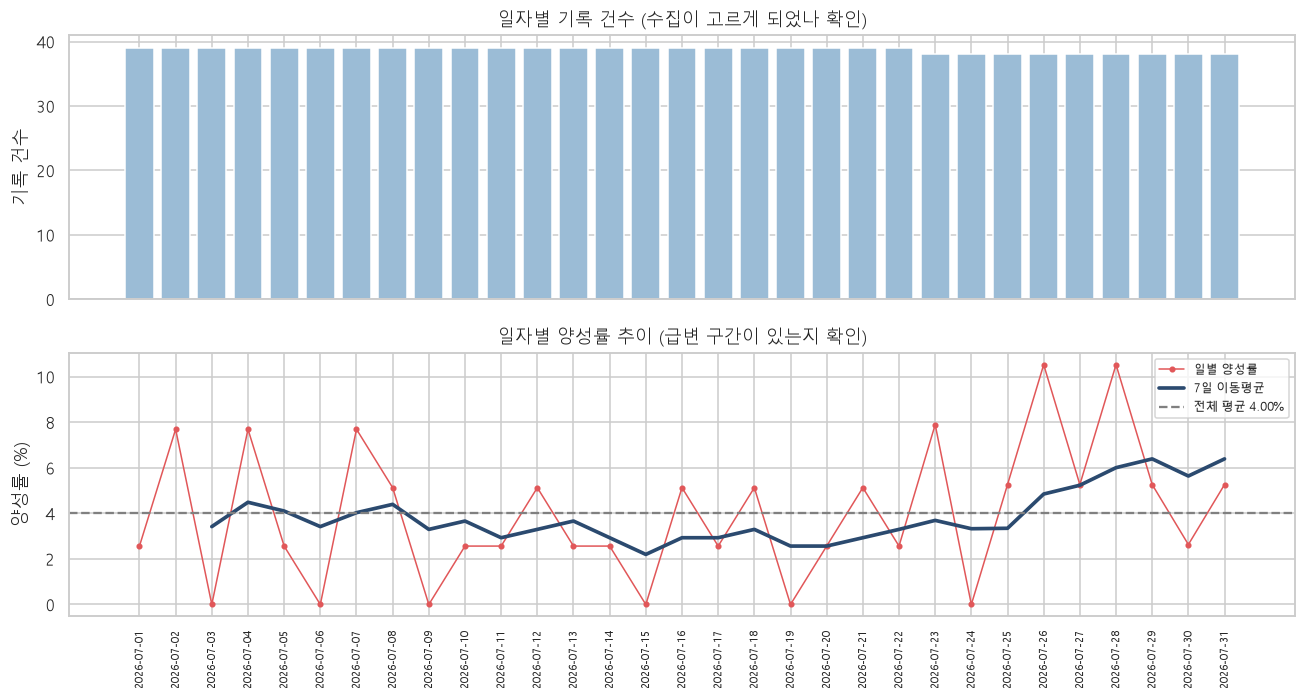

In [30]:
# =============================================================================
# [11-1] 일자별 건수와 양성률 추이
# =============================================================================
df["_ts"] = pd.to_datetime(df[TIME_COL])      # 시간 열을 datetime으로 변환
df["_date"] = df["_ts"].dt.date
df["_hour"] = df["_ts"].dt.hour
df["_dow"] = df["_ts"].dt.dayofweek           # 0=월 ... 6=일

daily = df.groupby("_date")["target"].agg(["size", "sum", "mean"])
daily.columns = ["건수", "양성건수", "양성률"]
daily["양성률"] = daily["양성률"] * 100
daily["양성률_7일평균"] = daily["양성률"].rolling(7, min_periods=3).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].bar(daily.index.astype(str), daily["건수"], color="#9bbcd6")
axes[0].set_ylabel("기록 건수")
axes[0].set_title("일자별 기록 건수 (수집이 고르게 되었나 확인)")
axes[0].tick_params(axis="x", rotation=90, labelsize=7)

axes[1].plot(daily.index.astype(str), daily["양성률"], marker="o", ms=3,
             lw=1, color="#e15759", label="일별 양성률")
axes[1].plot(daily.index.astype(str), daily["양성률_7일평균"], lw=2.4,
             color="#2b4a6f", label="7일 이동평균")
axes[1].axhline(df["target"].mean() * 100, color="gray", ls="--",
                label=f"전체 평균 {df['target'].mean()*100:.2f}%")
axes[1].set_ylabel("양성률 (%)")
axes[1].set_title("일자별 양성률 추이 (급변 구간이 있는지 확인)")
axes[1].legend(fontsize=8)
axes[1].tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout()
plt.show()

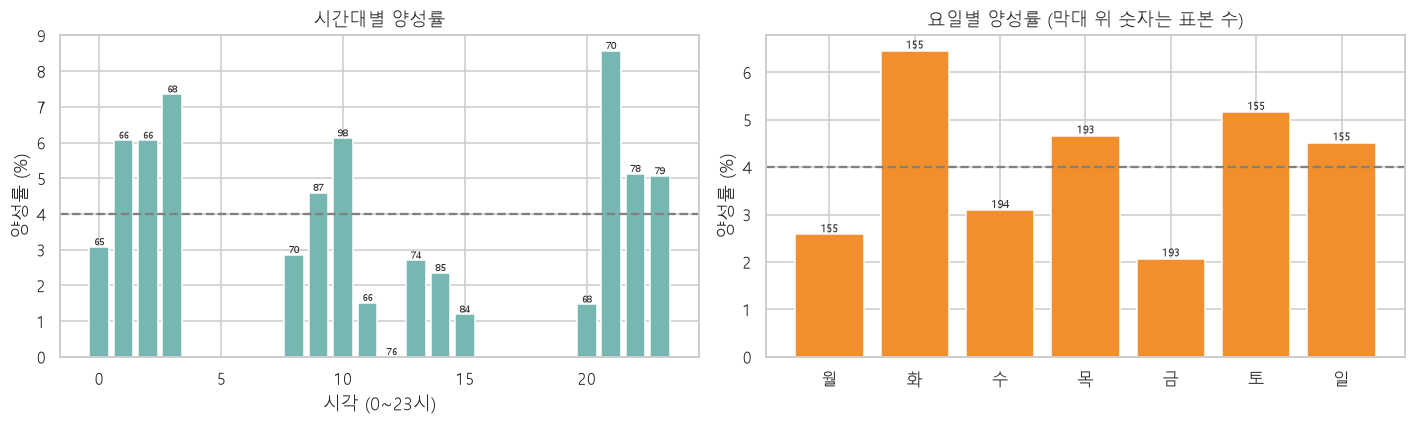

※ 막대 위 숫자는 표본 수다. 표본이 적은 구간의 비율은 크게 흔들리므로 주의한다.


In [31]:
# =============================================================================
# [11-2] 시간대(0~23시) / 요일별 양성률
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

hourly = df.groupby("_hour")["target"].agg(["size", "mean"])
axes[0].bar(hourly.index, hourly["mean"] * 100, color="#76b7b2")
axes[0].axhline(df["target"].mean() * 100, color="gray", ls="--")
axes[0].set_xlabel("시각 (0~23시)")
axes[0].set_ylabel("양성률 (%)")
axes[0].set_title("시간대별 양성률")
for x, (n, m) in zip(hourly.index, hourly.values):
    axes[0].text(x, m * 100, f"{int(n)}", ha="center", va="bottom", fontsize=6)

dow_name = ["월", "화", "수", "목", "금", "토", "일"]
dowly = df.groupby("_dow")["target"].agg(["size", "mean"])
axes[1].bar([dow_name[i] for i in dowly.index], dowly["mean"] * 100, color="#f28e2b")
axes[1].axhline(df["target"].mean() * 100, color="gray", ls="--")
axes[1].set_ylabel("양성률 (%)")
axes[1].set_title("요일별 양성률 (막대 위 숫자는 표본 수)")
for i, (n, m) in enumerate(dowly.values):
    axes[1].text(i, m * 100, f"{int(n)}", ha="center", va="bottom", fontsize=7)
plt.tight_layout()
plt.show()

print("※ 막대 위 숫자는 표본 수다. 표본이 적은 구간의 비율은 크게 흔들리므로 주의한다.")

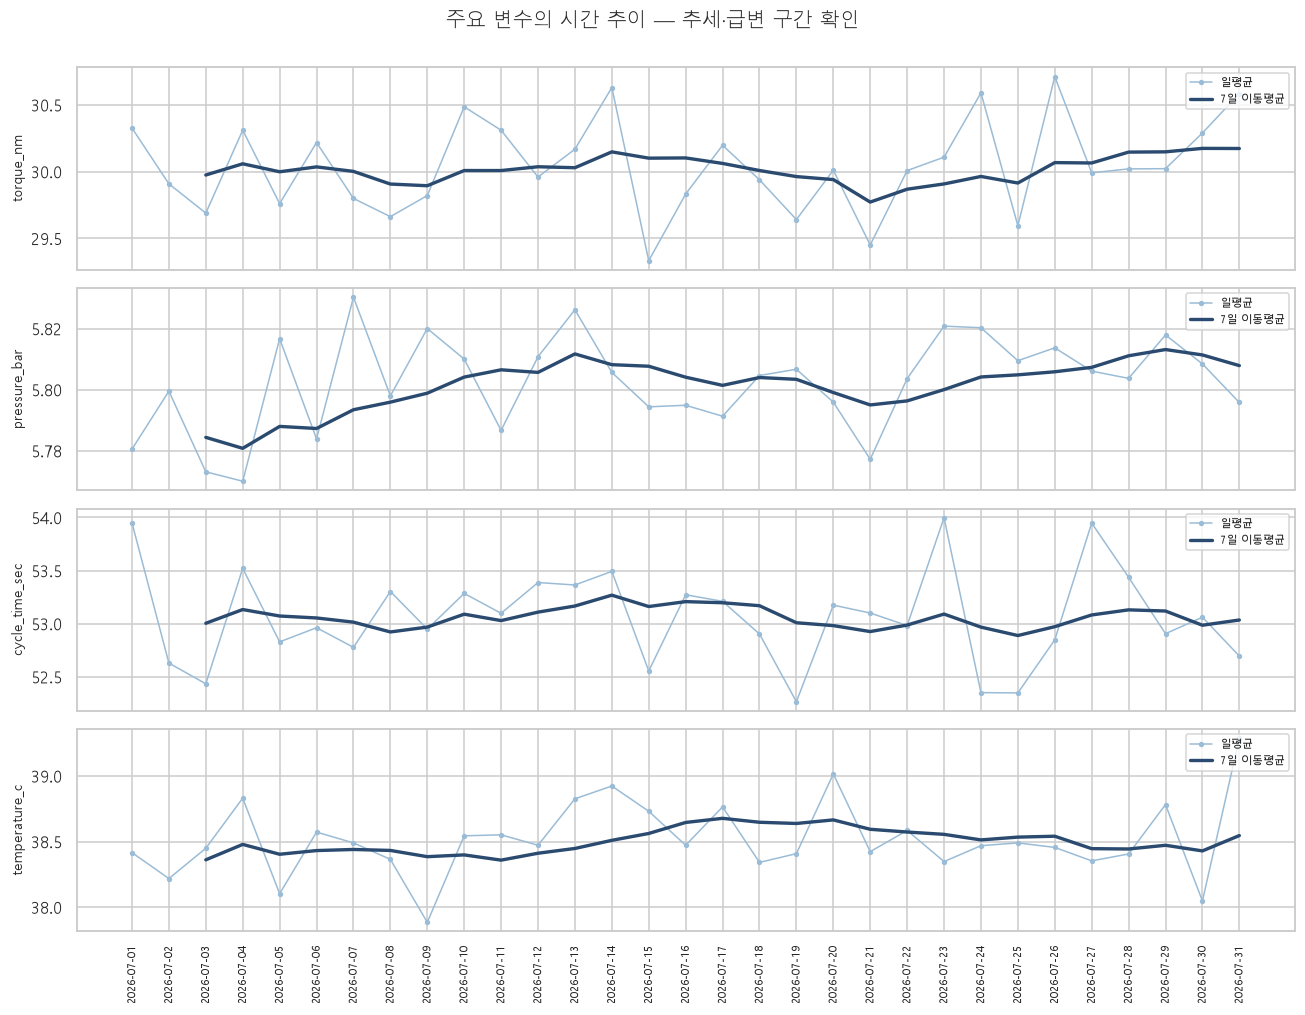

In [32]:
# =============================================================================
# [11-3] 주요 센서/운영 변수의 시간 추이 (이동평균)
# =============================================================================
trend_cols = [c for c in NUM_EDA[:4] if c in df.columns]
daily_num = df.groupby("_date")[trend_cols].mean()

fig, axes = plt.subplots(len(trend_cols), 1, figsize=(12, 2.3 * len(trend_cols)),
                         sharex=True)
axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, trend_cols):
    ax.plot(daily_num.index.astype(str), daily_num[c], lw=1, color="#9bbcd6",
            marker="o", ms=2.5, label="일평균")
    ax.plot(daily_num.index.astype(str),
            daily_num[c].rolling(7, min_periods=3).mean(), lw=2.2,
            color="#2b4a6f", label="7일 이동평균")
    ax.set_ylabel(c, fontsize=9)
    ax.legend(fontsize=7, loc="upper right")
axes[-1].tick_params(axis="x", rotation=90, labelsize=7)
fig.suptitle("주요 변수의 시간 추이 — 추세·급변 구간 확인", y=1.0)
plt.tight_layout()
plt.show()

---

## 12. 1편 정리 — 발견사항과 다음 단계

### 이 데이터에서 확인한 사실

- 전체 불량률 4.0%. **모두 합격이라고 찍어도 정확도 96%** 가 나오는 데이터다 →
  정확도만 보면 안 된다.
- 설비 M03의 불량률(7.33%)이 가장 높고, **정지시간 합계도 가장 크다(210분)**.
  설비팀이 먼저 확인할 대상이다.
- 체결토크 규격이탈(27~33 N·m 밖) 100건 중 **80건은 합격**이다. 규격이탈이 곧 불량은 아니다.
  반대로 불합격 48건 중 28건은 토크가 규격 안이다 → 토크 하나로는 부족하다.
- 공정압력, 사이클타임, 에너지사용량은 합격·불합격 평균 차이가 거의 없다.
  **"변수가 있다"와 "쓸모 있다"는 다르다.**
- 라인·제품모델은 효과를 분리할 수 없다(교란). 야간조는 원인이 아니라 **추가확인이 필요한 조건**이다.

### EDA 체크리스트 (캡스톤 제출물에 그대로 쓰세요)

| # | 항목 | 확인 |
|---|---|---|
| 1 | 데이터 크기·기간·분석단위를 한 문장으로 쓸 수 있다 | ☐ |
| 2 | 변수별 결측 건수와 **처리 방침**을 표로 정리했다 | ☐ |
| 3 | 중복(식별자·시각)을 확인했다 | ☐ |
| 4 | 물리적으로 불가능한 값을 찾아 목록화했다 | ☐ |
| 5 | **예측시점에 쓸 수 있는 변수**와 결과변수를 분리했다 | ☐ |
| 6 | 목표변수의 양성 비율과 **기준선 정확도**를 계산했다 | ☐ |
| 7 | 그룹별 양성률을 **표본 수와 함께** 정리했다 | ☐ |
| 8 | 교차표로 **교란 가능성**을 확인했다 | ☐ |
| 9 | 상관·산점도로 관계를 보고, **상관≠인과**를 명시했다 | ☐ |
| 10 | 시간 추세·주기·급변 구간을 확인했다 | ☐ |

### 2편(전처리·모델링)으로 가져갈 것

1. **정제 규칙** — 결측·불가능값 처리 방침 (코드로 고정)
2. **입력 변수 목록** — 예측시점에 쓸 수 있는 것만
3. **가설 목록** — "어떤 조건이 위험한가"에 대한 3~5개 문장
4. **평가 기준** — 정확도가 아니라 Recall/Precision 중 무엇을 우선할지

> **분석가의 태도**: 1편의 결론은 "무엇이 원인이다"가 아니라
> **"어디를 먼저 확인해야 한다"** 입니다. 관찰된 관계와 원인을 구분하는 것이
> 신뢰받는 분석가의 첫 번째 조건입니다.

---

## 연습문제 / 생각해 볼 질문

아래 문항은 정답을 맞히는 시험이 아니라, **발표자료에 쓸 문장을 만드는 연습**입니다.
코드를 조금씩 바꿔 보고, 결과를 한 문장으로 정리해 보세요.

1. `group_target_rate('operator_group')` 을 실행해 작업그룹별 불량률을 구하고, 가장 높은 그룹과 가장 낮은 그룹의 **표본 수**를 함께 적어 보세요. 표본 수가 적으면 왜 조심해야 할까요?
2. `shift`와 `equipment_id`를 교차한 불량률 표에서, '야간 M03'을 제외하면 야간조와 주간조의 불량률 차이가 얼마나 줄어드는지 계산해 보세요.
3. `torque_nm` 히스토그램에 27, 33 기준선을 그려 보고, 규격 밖 100건 중 합격이 80건이라는 사실을 그림으로 설명해 보세요.
4. `pressure_bar`, `energy_kwh` 를 합격/불합격으로 나눠 박스플롯을 그려 보세요. 이 두 변수는 왜 '불량 신호'로 쓰기 어렵나요?
5. `inspection_time_sec`(검사시간)으로 합격/불합격을 비교해 보세요. 차이가 보이더라도 이 변수를 예측모델에 쓰면 안 되는 이유를 한 문장으로 쓰세요.

> 답을 적을 때는 반드시 **숫자(건수·비율)** 를 함께 쓰세요.
> "야간이 더 나쁘다" 보다 "야간 30/560건(5.36%) vs 주간 18/640건(2.81%)" 이
> 현장에서 신뢰받는 문장입니다.

---

### 다음 노트북

**[01-2] 전처리 · 머신러닝 모델 · 성능평가** 에서는
이 노트북에서 정한 규칙을 코드로 고정하고, 로지스틱 회귀 · 의사결정나무 ·
랜덤포레스트를 학습시켜 혼동행렬과 ROC-AUC로 비교합니다.